In [1]:
import pandas as pd
import numpy as np
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt

import umap
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder

sc.settings.verbosity = 3
sc.set_figure_params(figsize=(8.5, 8), dpi=150)

/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
colors = [
'#B691BE',
'#D1D257',
'#7DA8EE',
'#F5E182',
'#e07b91',
'#8dd593',
'#e6afb9',
'#ead3c6',
'#c6dec7', 
'#4a6fe3',
'#ef9708',
'#d33f6a',
'#11c638',
'#0fcfc0',  
'#9cded6',
'#d5eae7',
'#f3e1eb',
'#f6c4e1',
'#023fa5',
'#7d87b9',
'#bec1d4',
'#d6bcc0',
'#bb7784',
'#8e063b',
  ]

# Load files

In [3]:
adata1 = sc.read_h5ad('../../processed_data/l1000_mdmt_full_336852.h5ad')
adata1

AnnData object with n_obs × n_vars = 336852 × 978
    obs: 'sample_id', 'bead_batch', 'nearest_dose', 'pert_dose', 'pert_dose_unit', 'pert_idose', 'pert_time', 'pert_itime', 'pert_time_unit', 'cell_mfc_name', 'pert_mfc_id', 'det_plate', 'det_well', 'rna_plate', 'rna_well', 'count_mean', 'count_cv', 'qc_f_logp', 'qc_iqr', 'qc_slope', 'pert_id', 'pert_type', 'cell_iname', 'qc_pass', 'dyn_range', 'inv_level_10', 'build_name', 'failure_mode', 'project_code', 'cmap_name', 'pert_dose_idx', 'n_replicates', 'pert_idx', 'cell_idx', 'tissue_idx', 'tissue', 'cell_pert_dose_time', 'pretrain_split', 'split_breast_1', 'split_breast_2', 'split_breast_3', 'split_breast_4', 'split_breast_5', 'split_lung_1', 'split_lung_2', 'split_lung_3', 'split_lung_4', 'split_lung_5', 'split_haematopoietic_and_lymphoid_tissue_1', 'split_haematopoietic_and_lymphoid_tissue_2', 'split_haematopoietic_and_lymphoid_tissue_3', 'split_haematopoietic_and_lymphoid_tissue_4', 'split_haematopoietic_and_lymphoid_tissue_5'
    var

In [4]:
adata2 = sc.read_h5ad('../../processed_data/CDSDB_mdmt_613.h5ad')
adata2

AnnData object with n_obs × n_vars = 613 × 978
    obs: 'Sample ID', 'Base/Post', 'CDS-DB patient signature list', 'CDS-DB dataset list', 'Patient ID', 'Sampling location', 'Sampling time', 'Annotation of the therapeutic regimen from the data source', 'Therapeutic Regimen Recorded In The Data Source', 'Therapeutic regimen', 'Therapeutic regimen ID', 'Administration dose', 'Additional information about the therapeutic regimen', 'Drug category', 'Source dataset', 'Source database', 'Reference (PubMed ID)', 'Data type', 'Platform', 'Cancer subtype recorded in the data source', 'Cancer subtype', 'DOID of cancer subtype', 'Sampling location category', 'Additional information about the cancer', 'Original response status', 'Response group', 'Pediatric oncology', 'Predefined grouping criteria of response and non-response groups', 'Drug category_compact', 'sample_id_unique', 'pair_match_id', 'pert_time', 'pert_time_idx', 'pert_dose', 'pert_dose_unit', 'pert_dose_idx', 'pert_id', 'pert_idx', 'ti

In [5]:
cancer_subtypes_order = [
    'Breast cancer',
    'Her2-receptor negative breast cancer',
    'Estrogen-receptor positive breast cancer',
    'Invasive ductal carcinoma',
    'Invasive lobular carcinoma',
    'Chronic myeloid leukemia',
    'Chronic lymphocytic leukemia',
    'Childhood B-cell acute lymphoblastic leukemia',
    'Childhood T-cell acute lymphoblastic leukemia',
    'Acute myeloid leukemia',
    'Ovarian cancer',
    'Gastrointestinal stromal tumor',
    'Melanoma',
    'Alveolar soft part sarcoma'
]

adata2.obs['Cancer subtype'] = pd.Categorical(
    adata2.obs['Cancer subtype'], categories=cancer_subtypes_order, ordered=True
)

adata2 = adata2[adata2.obs['Cancer subtype'].cat.codes.argsort()]

In [9]:
adata2_ctl = sc.AnnData(X=adata2.obsm['X_ctl'], obs=adata2.obs, var=adata2.var)
adata2_ctl

AnnData object with n_obs × n_vars = 613 × 978
    obs: 'Sample ID', 'Base/Post', 'CDS-DB patient signature list', 'CDS-DB dataset list', 'Patient ID', 'Sampling location', 'Sampling time', 'Annotation of the therapeutic regimen from the data source', 'Therapeutic Regimen Recorded In The Data Source', 'Therapeutic regimen', 'Therapeutic regimen ID', 'Administration dose', 'Additional information about the therapeutic regimen', 'Drug category', 'Source dataset', 'Source database', 'Reference (PubMed ID)', 'Data type', 'Platform', 'Cancer subtype recorded in the data source', 'Cancer subtype', 'DOID of cancer subtype', 'Sampling location category', 'Additional information about the cancer', 'Original response status', 'Response group', 'Pediatric oncology', 'Predefined grouping criteria of response and non-response groups', 'Drug category_compact', 'sample_id_unique', 'pair_match_id', 'pert_time', 'pert_time_idx', 'pert_dose', 'pert_dose_unit', 'pert_dose_idx', 'pert_id', 'pert_idx', 'ti

In [6]:
adata1_breast = adata1[adata1.obs.tissue=='breast']
adata1_breast_ctl = sc.AnnData(X=adata1_breast.obsm['X_ctl'], obs=adata1_breast.obs, var=adata1_breast.var)

adata1_breast.n_obs

55130

In [7]:
adata2_breast = adata2[adata2.obs.tissue=='breast']
adata2_breast_ctl = sc.AnnData(X=adata2_breast.obsm['X_ctl'], obs=adata2_breast.obs, var=adata2_breast.var)

adata2_breast.n_obs

357

In [18]:
adata1_leukemia = adata1[adata1.obs.tissue=='haematopoietic_and_lymphoid_tissue']
adata1_leukemia_ctl = sc.AnnData(X=adata1_leukemia.obsm['X_ctl'], obs=adata1_leukemia.obs, var=adata1_leukemia.var)

adata1_leukemia.n_obs

19877

In [20]:
adata2_leukemia = adata2[adata2.obs.tissue=='haematopoietic_and_lymphoid_tissue']
adata2_leukemia_ctl = sc.AnnData(X=adata2_leukemia.obsm['X_ctl'], obs=adata2_leukemia.obs, var=adata2_leukemia.var)
adata2_leukemia.n_obs

196

In [153]:
adata1.obs.tissue.value_counts()

tissue
breast                                55130
lung                                  45481
prostate                              39501
skin                                  29598
kidney                                26458
unknown                               26050
large_intestine                       24106
haematopoietic_and_lymphoid_tissue    19877
cervix                                12143
liver                                 10864
pancreas                               9086
endometrium                            8714
central_nervous_system                 7076
soft_tissue                            6178
bone                                   5554
ovary                                  4939
urinary_tract                          3700
stomach                                1022
autonomic_ganglia                       729
placenta                                348
upper_aerodigestive_tract               298
Name: count, dtype: int64

In [154]:
adata2.obs.tissue.value_counts()

tissue
breast                                357
haematopoietic_and_lymphoid_tissue    196
ovary                                  27
stomach                                18
skin                                    9
soft_tissue                             6
Name: count, dtype: int64

In [12]:
np.intersect1d(adata2.obs.pert_idx.values, adata1.obs.pert_idx.values).shape

(13,)

In [33]:
np.intersect1d(adata2.obs.tissue.values, adata1.obs.tissue.values).shape

(5,)

# Visualize CDS_DB dataset

In [8]:
cancer_color_dict = {
    'Breast cancer': '#ECC50F',
    'Her2-receptor negative breast cancer': '#EDCF40',
    'Estrogen-receptor positive breast cancer': '#F5E182',
    'Invasive ductal carcinoma': '#F8E89E',
    'Invasive lobular carcinoma': '#FBF1C5',
    'Chronic myeloid leukemia': '#3074E4',
    'Chronic lymphocytic leukemia': '#5990EA',
    'Childhood B-cell acute lymphoblastic leukemia': '#7DA8EE',
    'Childhood T-cell acute lymphoblastic leukemia': '#A7C4F4',
    'Acute myeloid leukemia': '#D2E0FA',
    'Ovarian cancer': '#B691BE',
    'Gastrointestinal stromal tumor': '#CCCCFF',
    'Melanoma': '#D1D257',
    'Alveolar soft part sarcoma': '#C69E32'
}

computing PCA
    with n_comps=40
    finished (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 40
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:01)


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


<Axes: title={'center': 'Cancer subtype'}, xlabel='tSNE1', ylabel='tSNE2'>

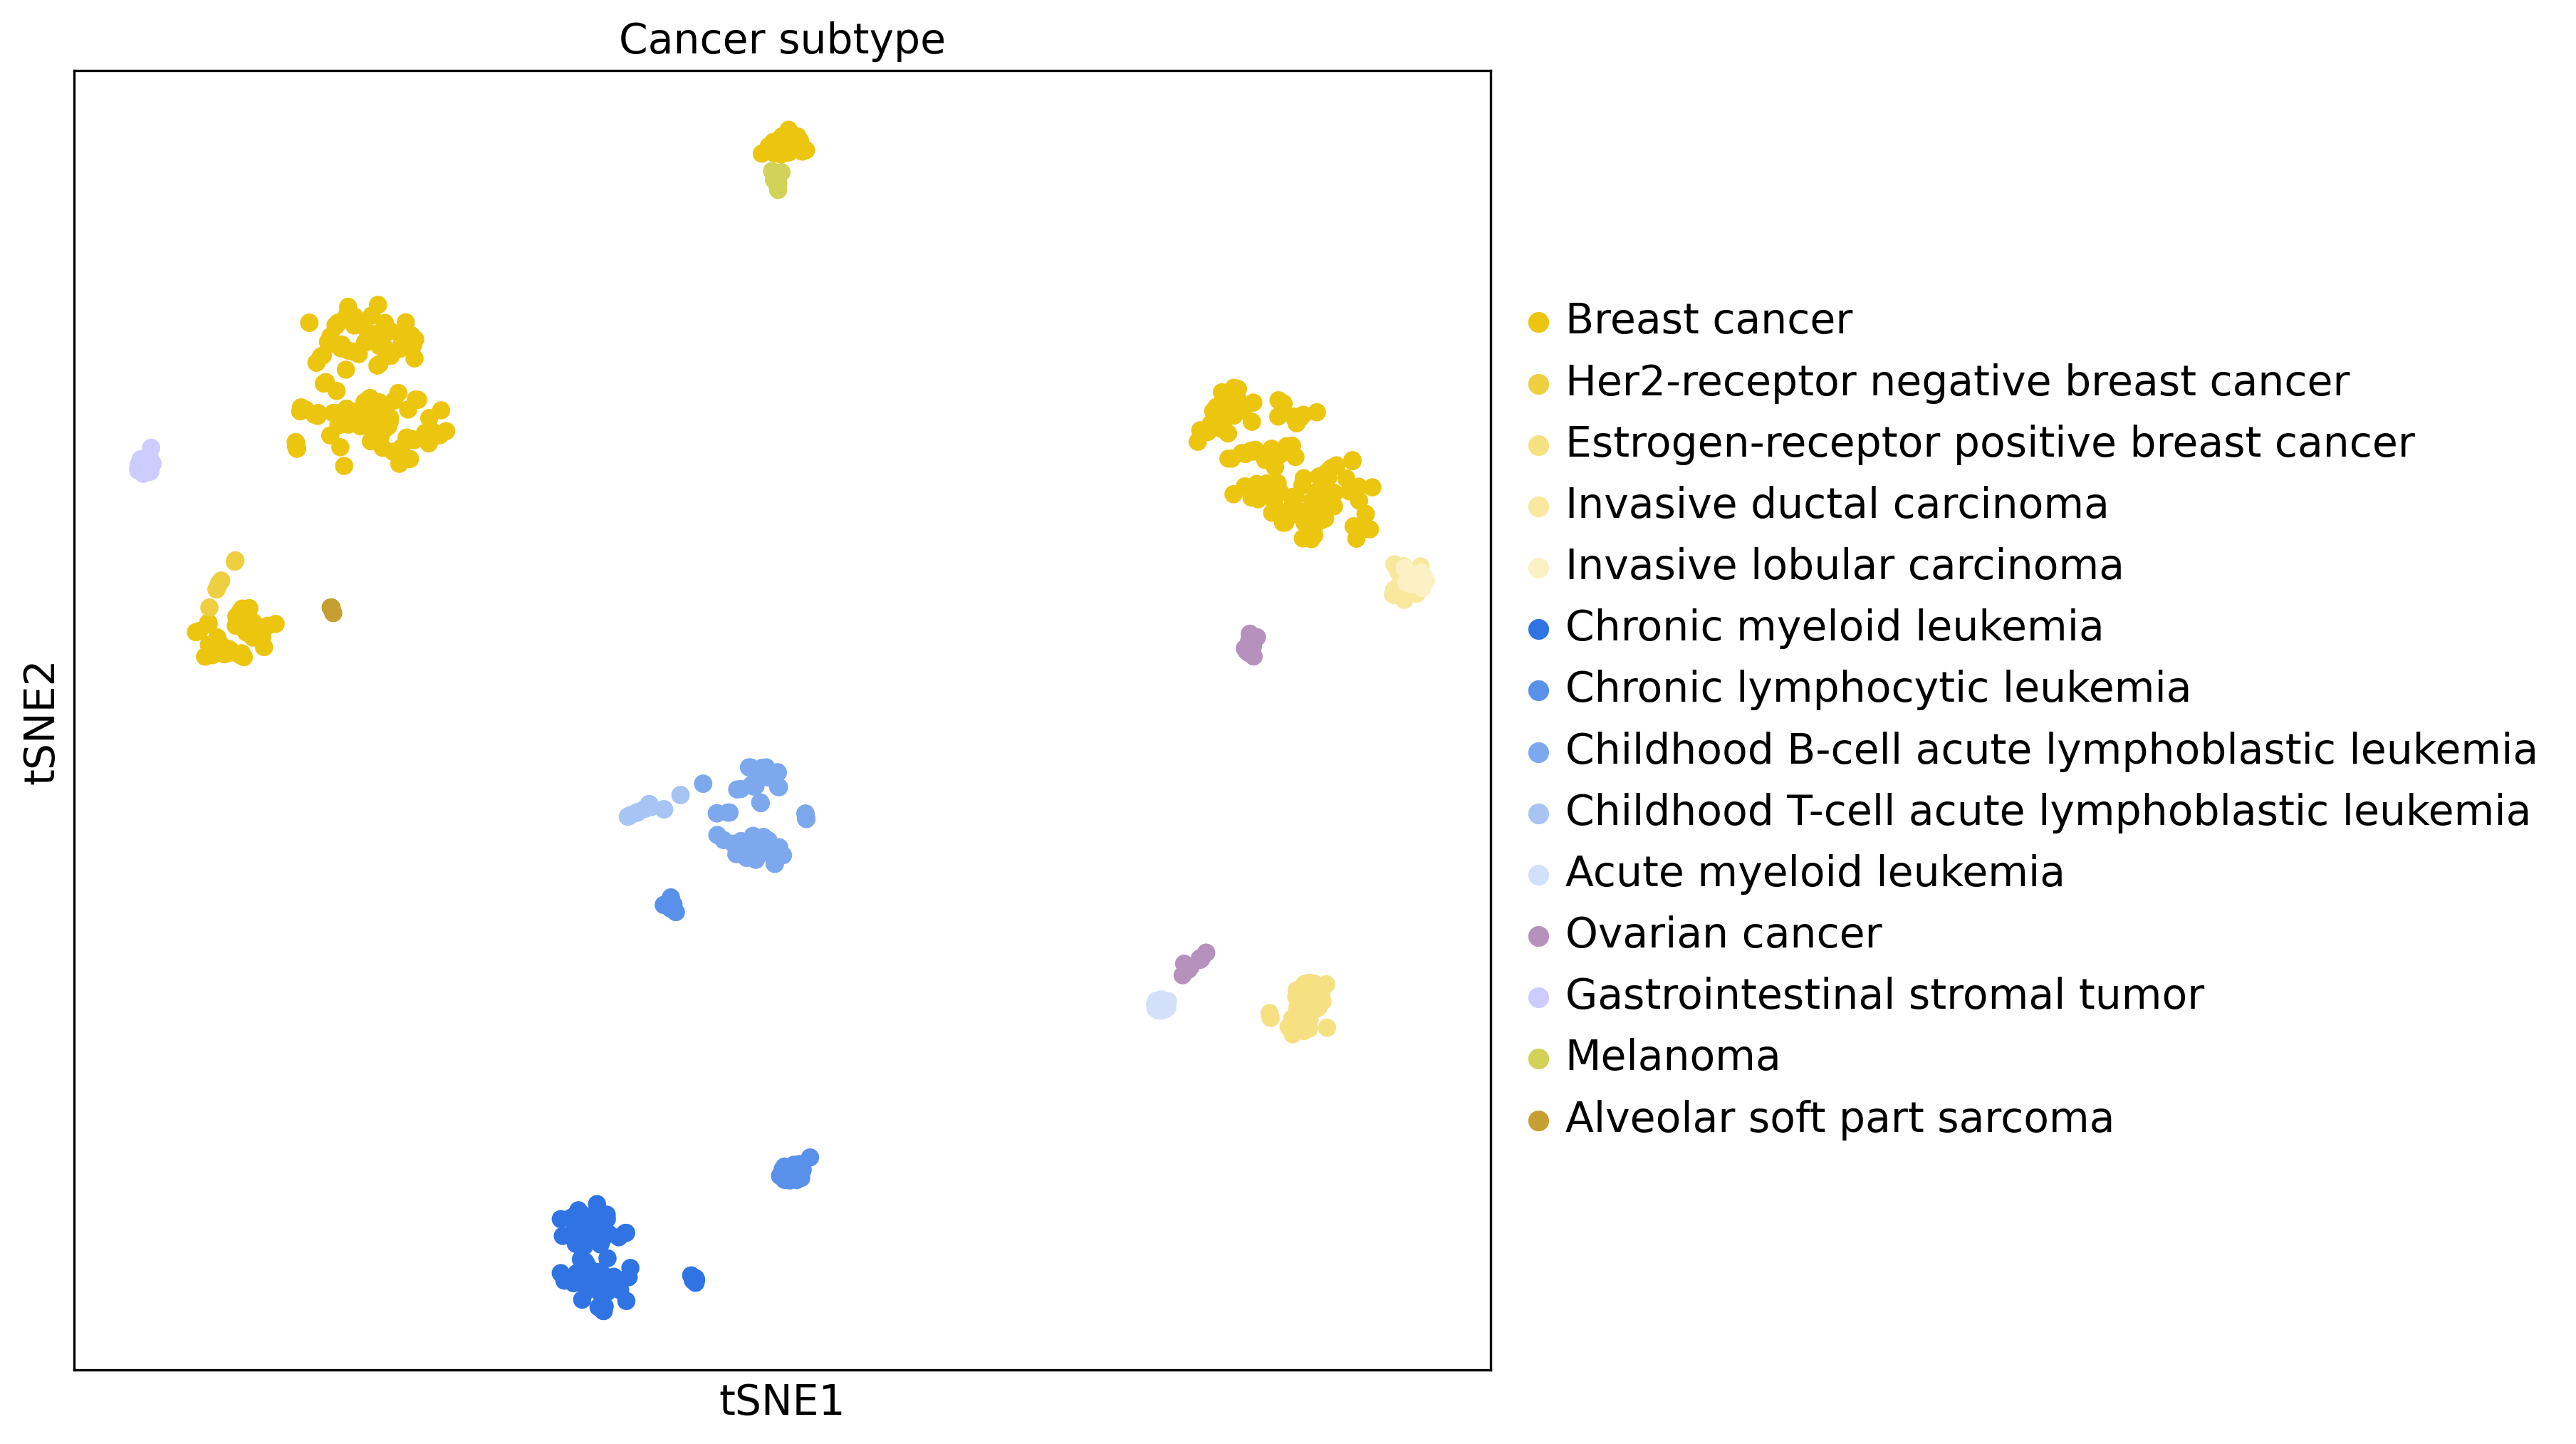

In [11]:
sc.pp.pca(adata2, n_comps=40)
sc.pp.neighbors(adata2, n_neighbors=15, use_rep='X_pca')
sc.tl.tsne(adata2)

sc.pl.tsne(adata2, color=["Cancer subtype"], wspace=0.4, legend_fontsize=14, palette=cancer_color_dict, size=150, show=False)

# plt.savefig("figs/tsne_cdsdb_trt_cancer.svg", format="svg", dpi=300, bbox_inches="tight")

/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


<Axes: title={'center': 'pert_id'}, xlabel='tSNE1', ylabel='tSNE2'>

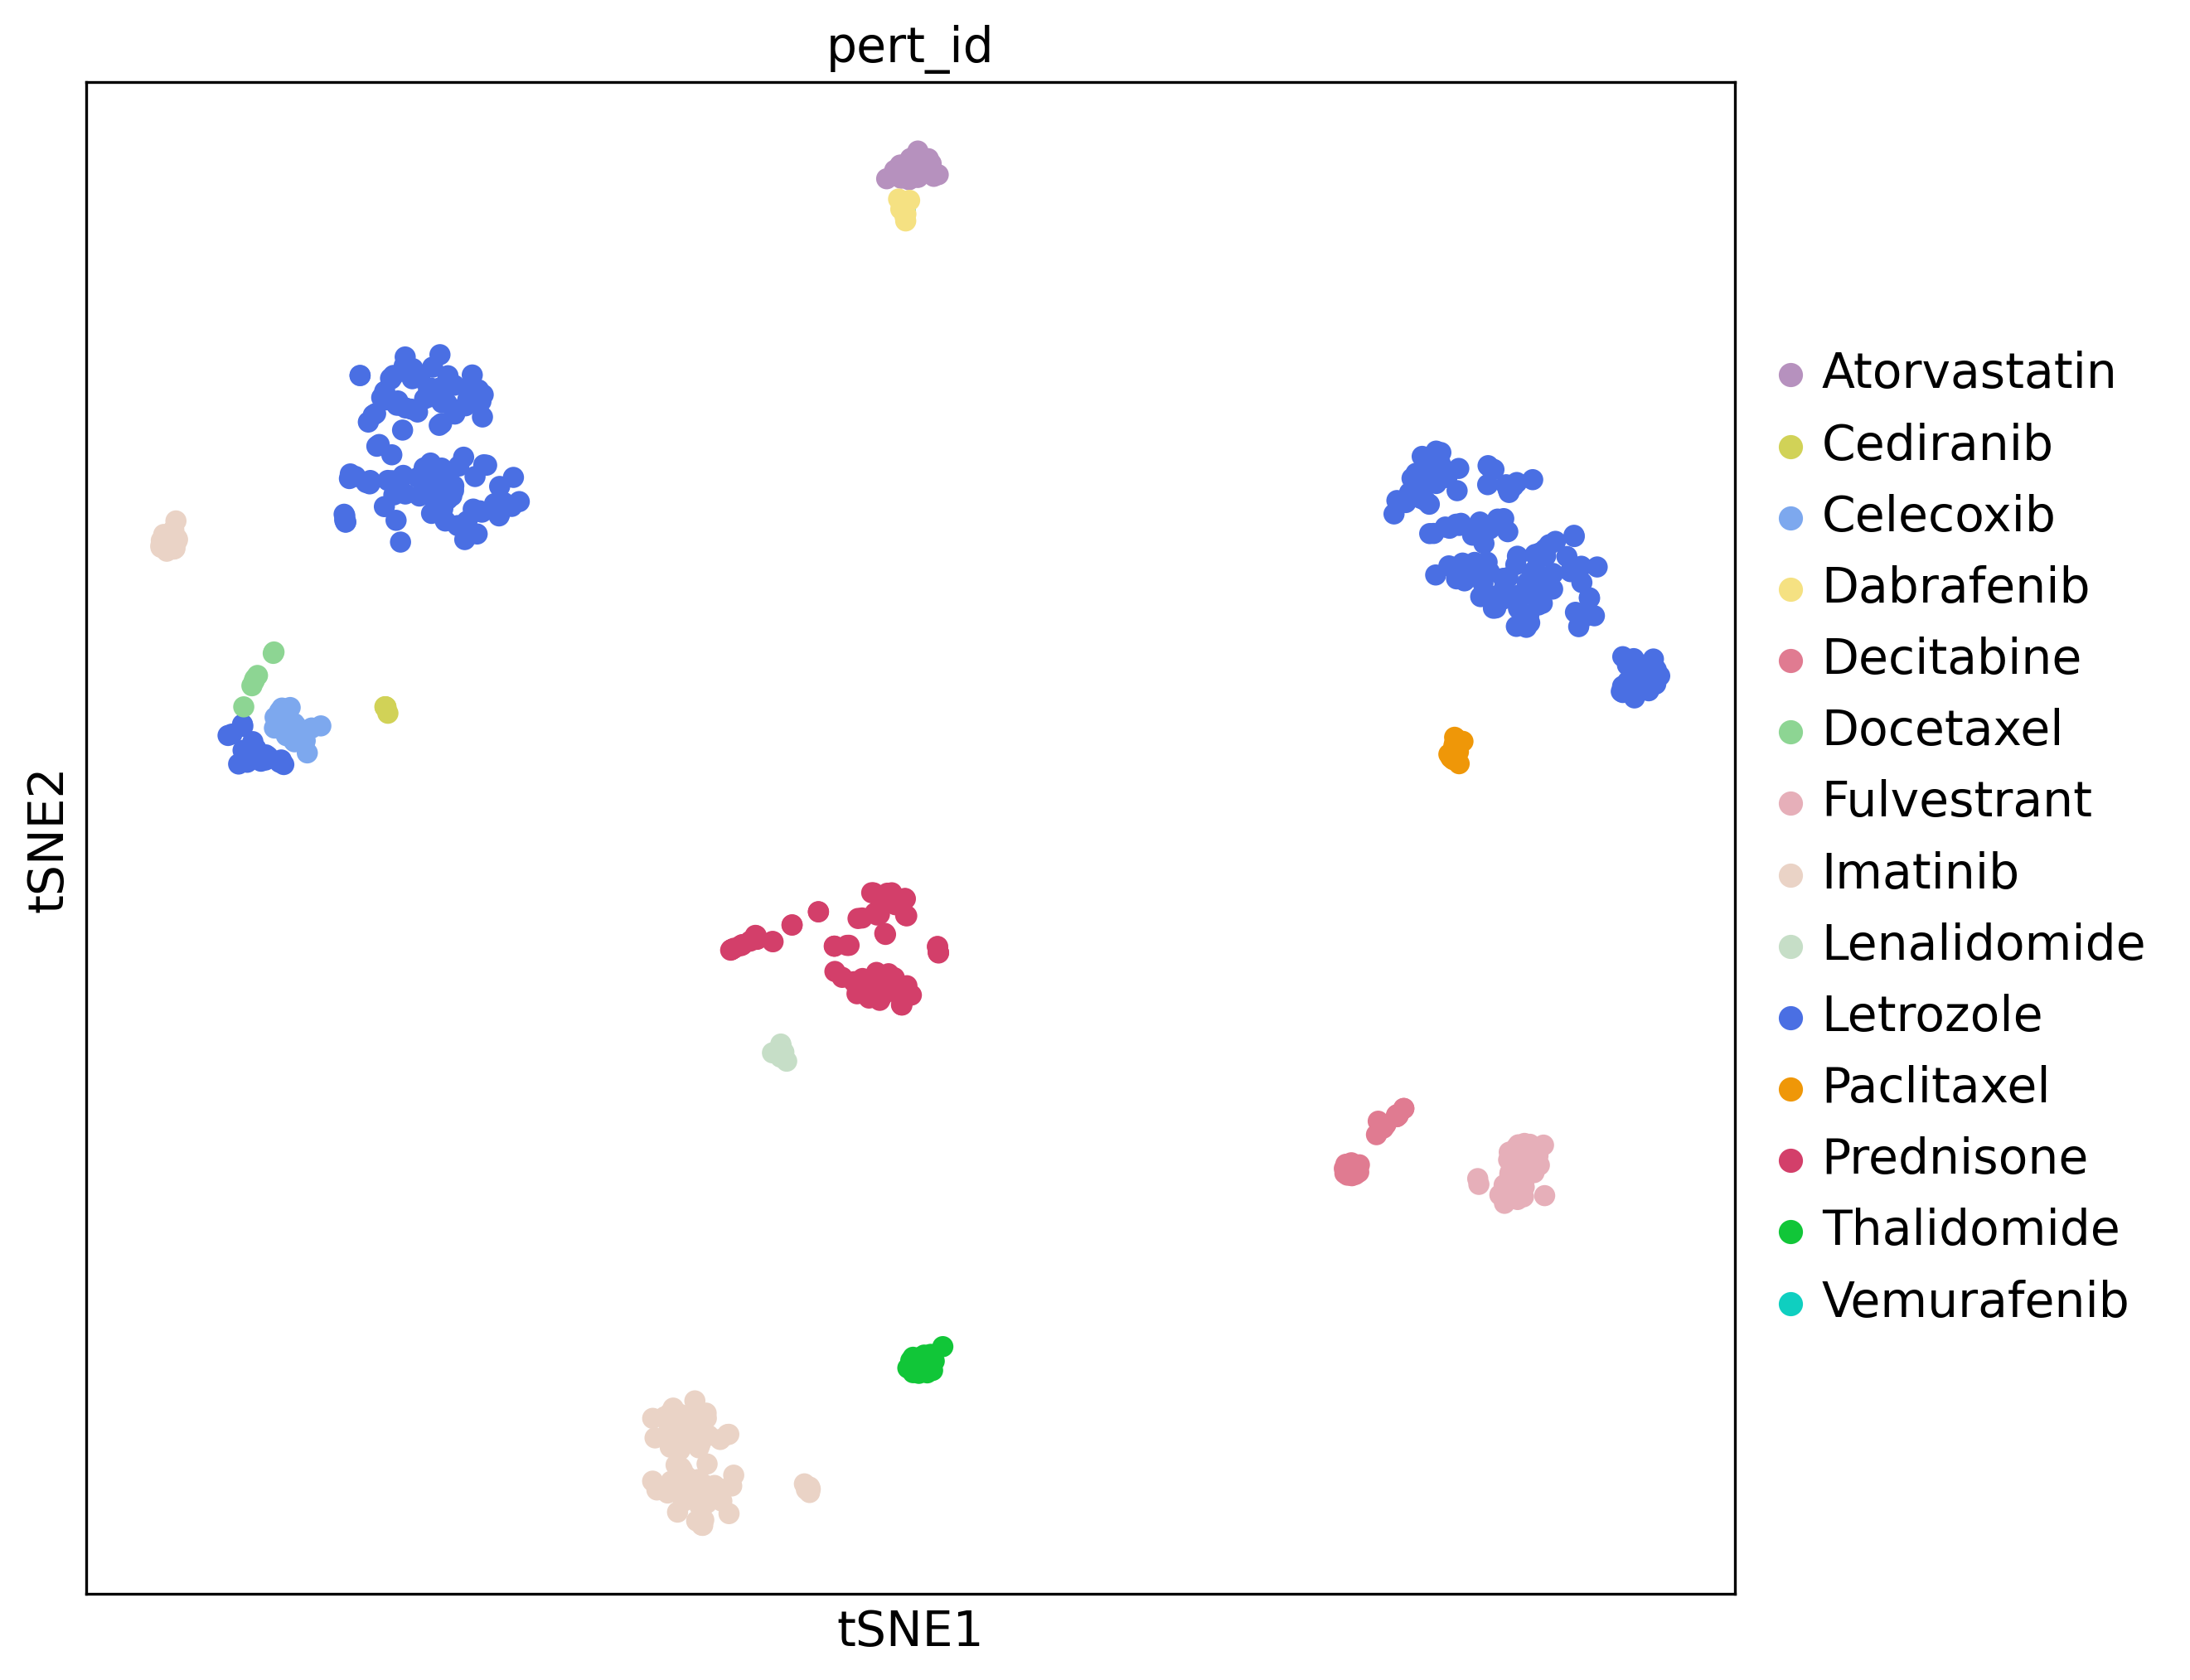

In [13]:
sc.pl.tsne(adata2, color=["pert_id"], wspace=0.4, legend_fontsize=14, palette=colors, size=150, show=False)

# plt.savefig("figs/tsne_cdsdb_trt_pert.svg", format="svg", dpi=300, bbox_inches="tight")

computing PCA
    with n_comps=40
    finished (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 40
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:01)


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


<Axes: title={'center': 'Cancer subtype'}, xlabel='tSNE1', ylabel='tSNE2'>

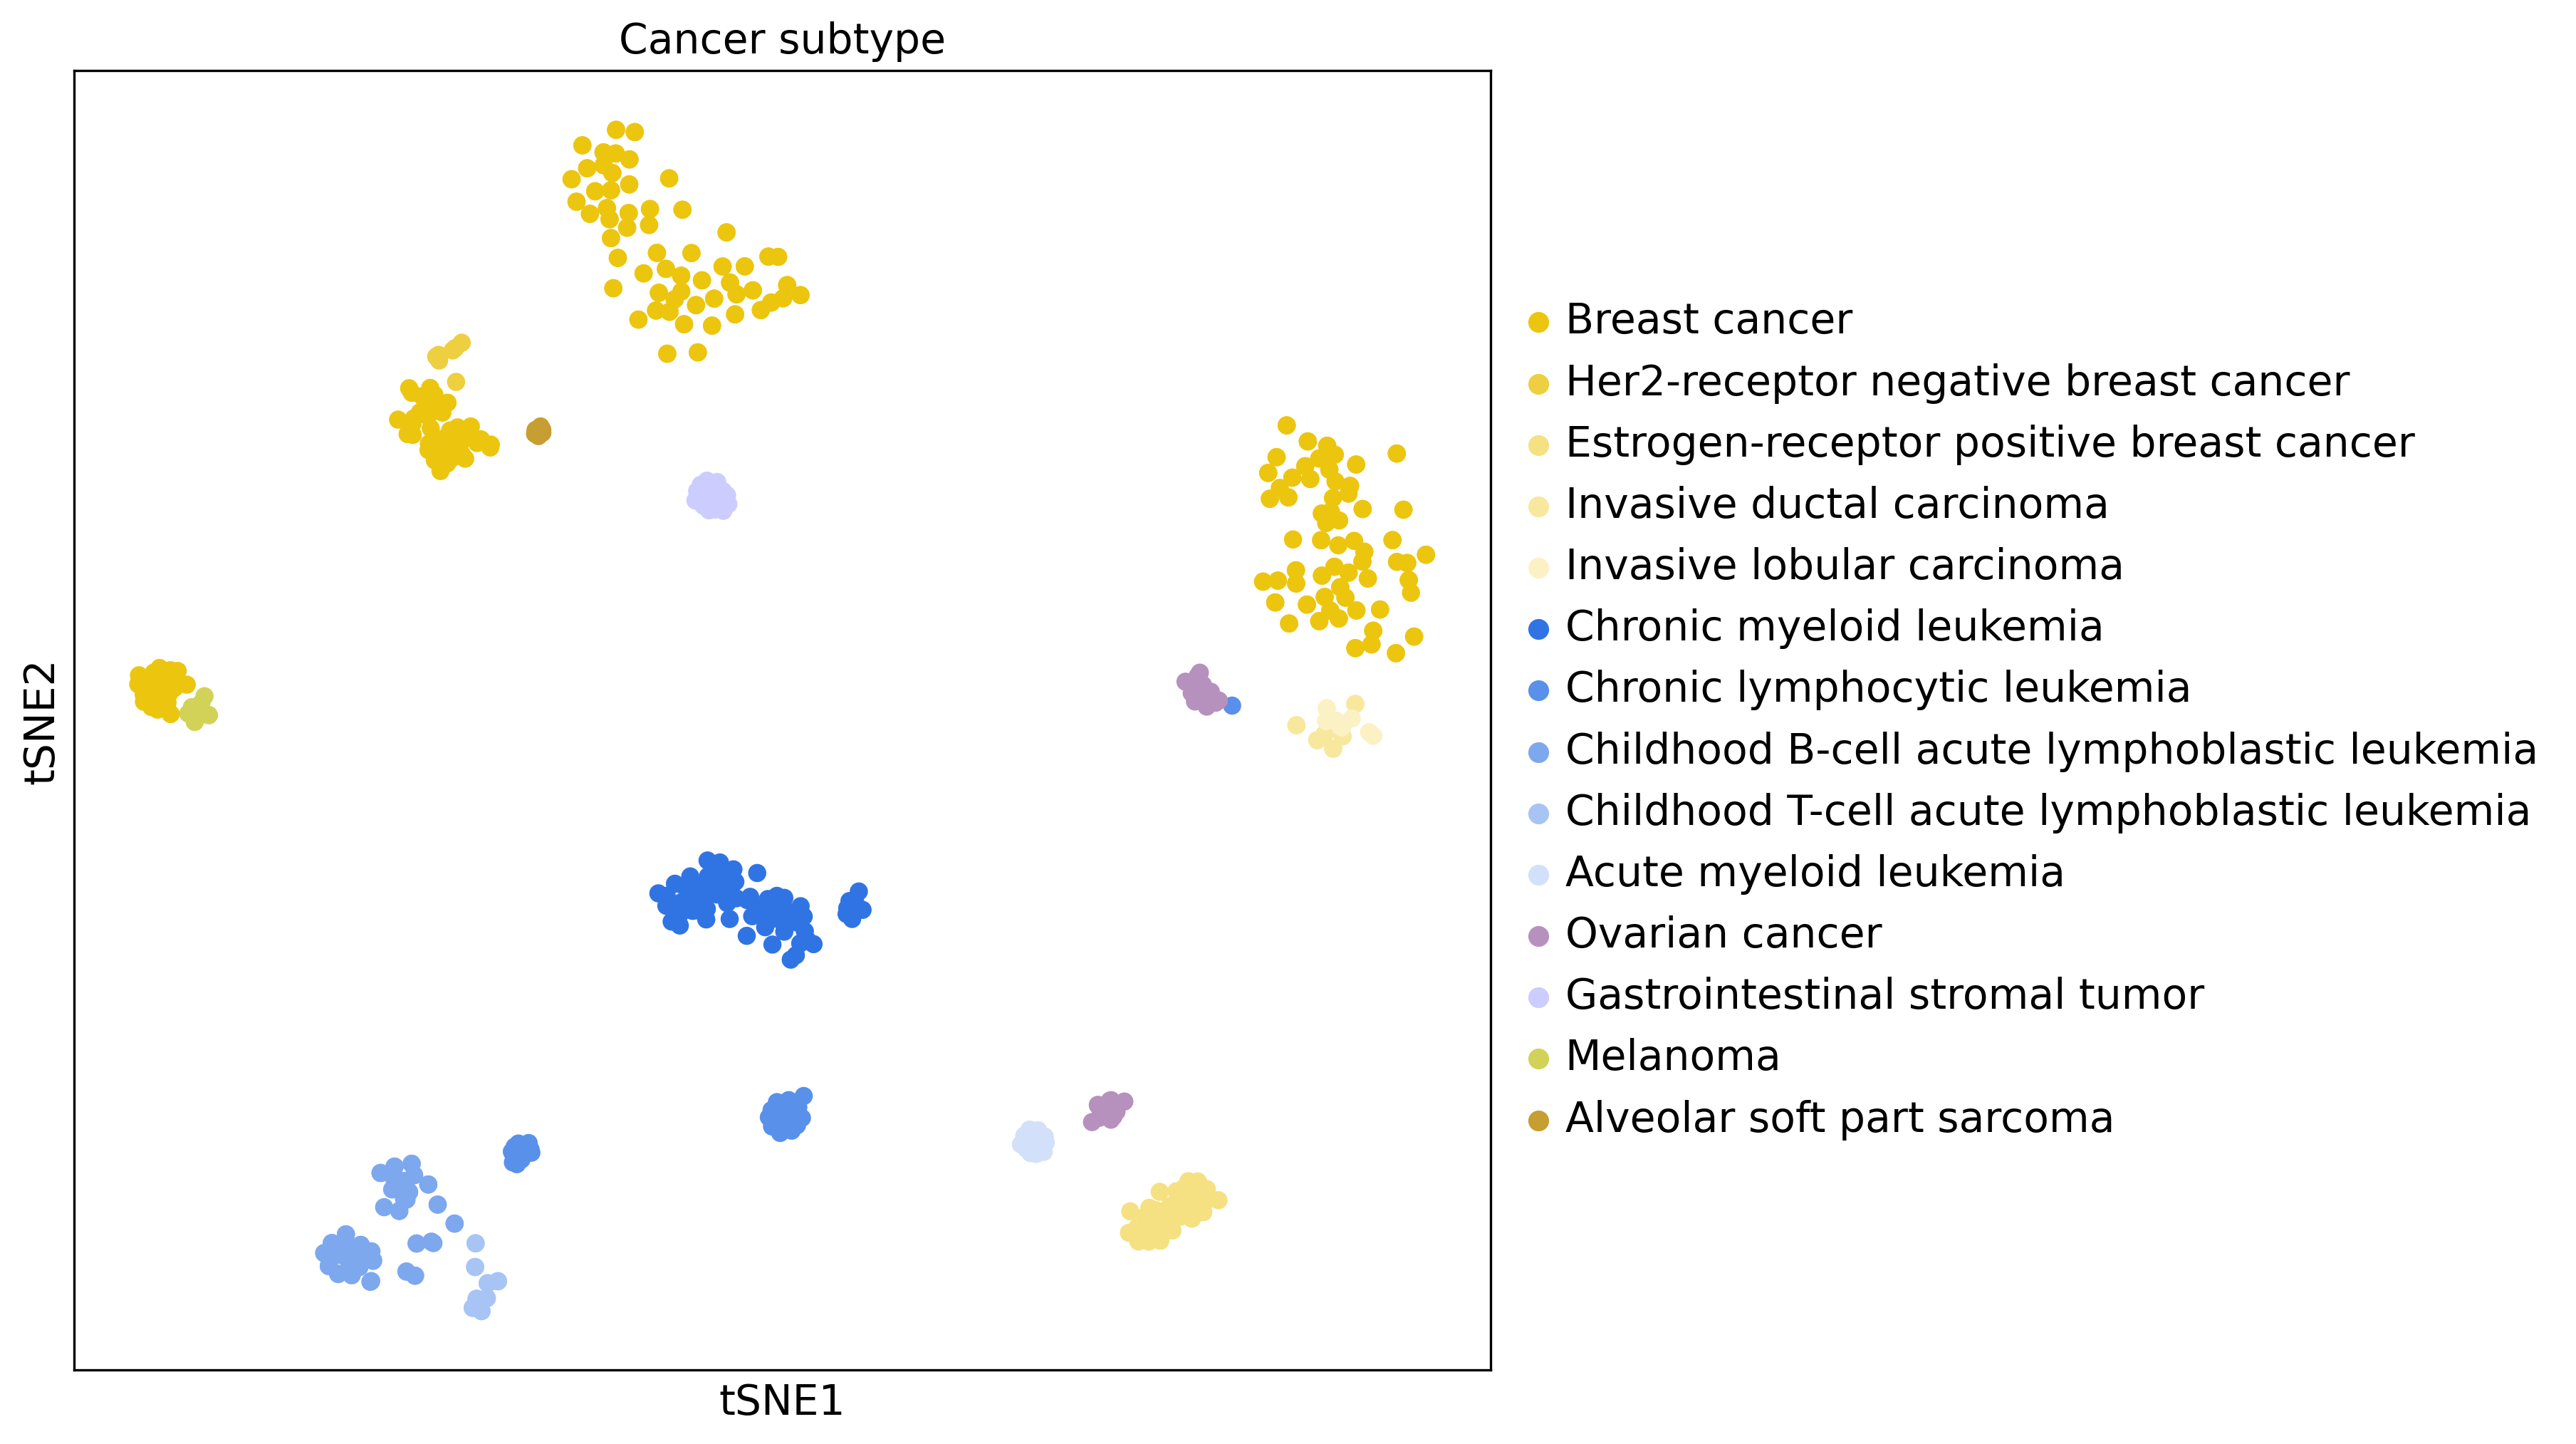

In [21]:
sc.pp.pca(adata2_ctl, n_comps=40)
sc.pp.neighbors(adata2_ctl, n_neighbors=15, use_rep='X_pca')
sc.tl.tsne(adata2_ctl)

sc.pl.tsne(adata2_ctl, color=["Cancer subtype"], wspace=0.4, legend_fontsize=14, palette=cancer_color_dict, size=150, show=False)

# plt.savefig("figs/tsne_cdsdb_ctl_cancer.svg", format="svg", dpi=300, bbox_inches="tight")

computing PCA
    with n_comps=40
    finished (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 40
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:00)


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


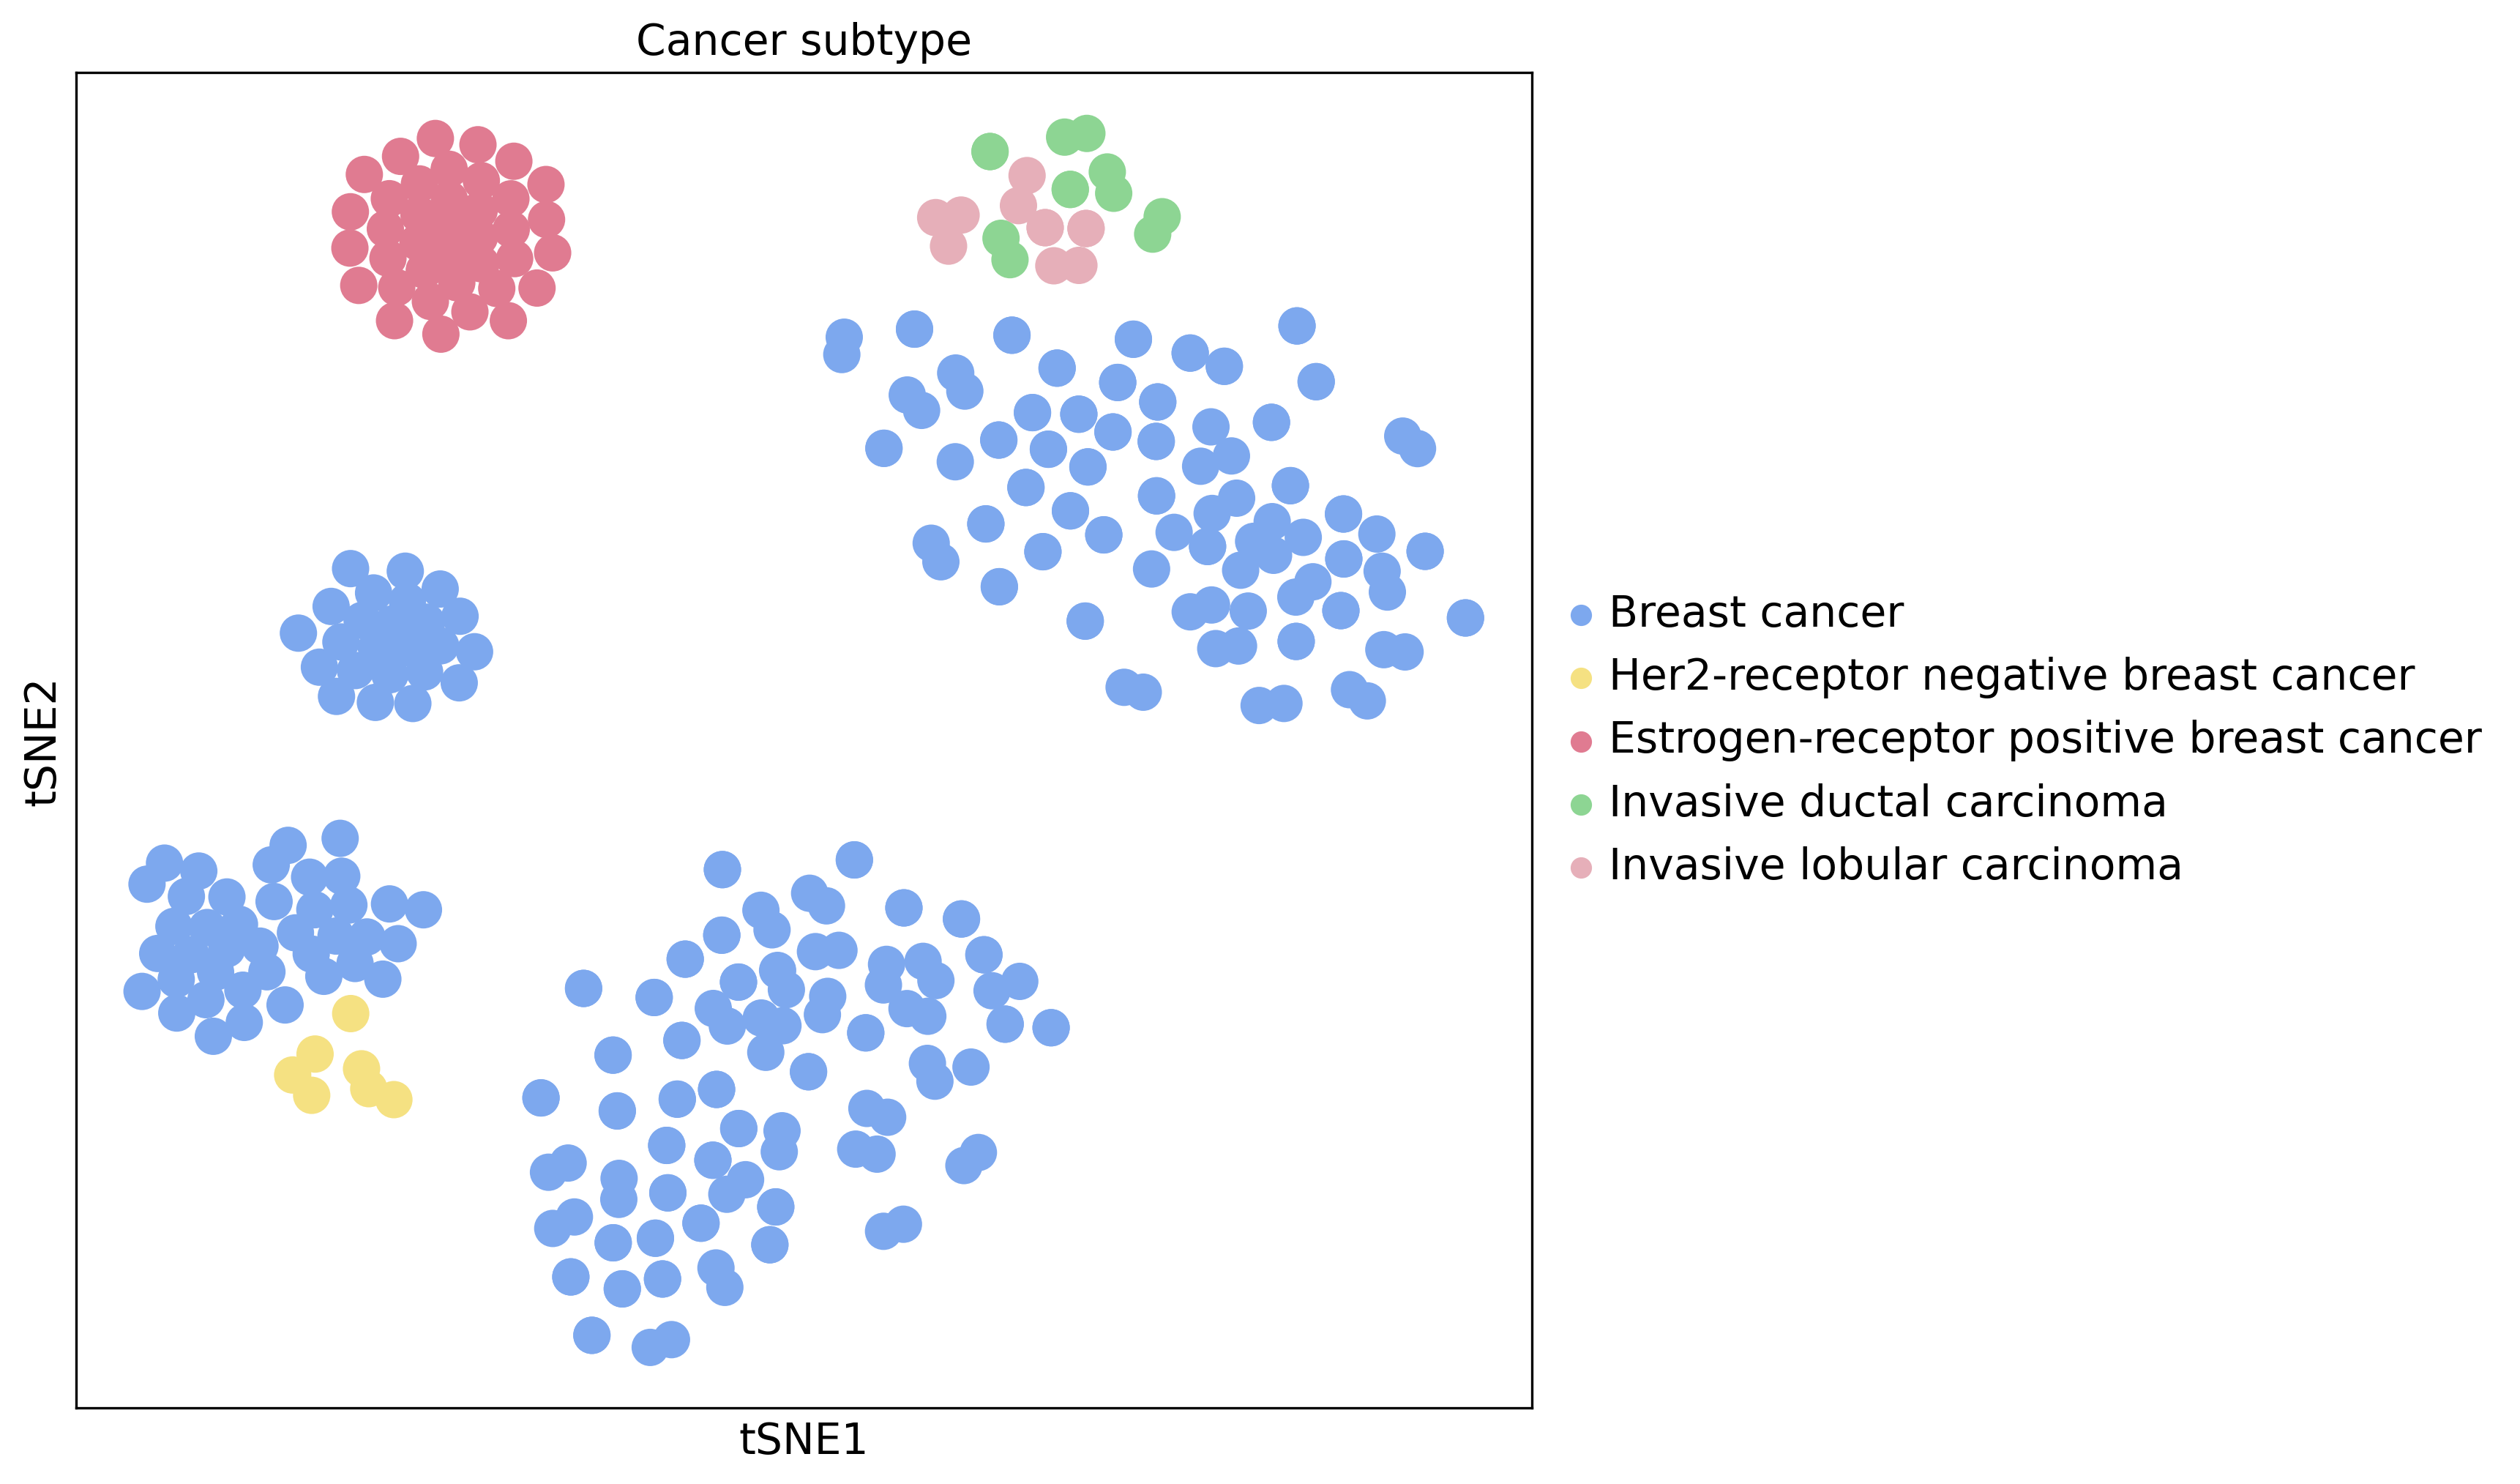

In [22]:
sc.pp.pca(adata2_breast_ctl, n_comps=40)
sc.pp.neighbors(adata2_breast_ctl, n_neighbors=15, use_rep='X_pca')
sc.tl.tsne(adata2_breast_ctl,
           perplexity=40,
           learning_rate=200, 
          )

sc.pl.tsne(adata2_breast_ctl, color=["Cancer subtype"], wspace=0.3, legend_fontsize=14, palette=colors[2:], s=600,
          show=False)

# plt.savefig("figs/tsne_cdsdb_breast_ctl_cancer.svg", format="svg", dpi=300, bbox_inches="tight")

plt.show()

# Visualize pre-treament space (L1000_breast & cdsdb_breast)

In [26]:
a1 = adata1_breast
a2 = adata2_breast

In [36]:
X_merge = np.concatenate((a1.obsm['X_ctl'], a2.obsm['X_ctl']), axis=0)

info1 = a1.obs[['cell_iname', 'tissue']].copy()
info2 = a2.obs[['Cancer subtype', 'tissue']].copy()
info1.loc[:, 'source'] = 'L1000'
info2.loc[:, 'source'] = 'CDS_DB'
info_merge = pd.concat([info1, info2], axis=0)

plot_adata = sc.AnnData(X=X_merge)
plot_adata.obs = info_merge

plot_adata

AnnData object with n_obs × n_vars = 55487 × 978
    obs: 'cell_iname', 'tissue', 'source', 'Cancer subtype'

In [46]:
sc.pp.pca(plot_adata, n_comps=40)
sc.pp.neighbors(plot_adata, n_neighbors=50, use_rep='X_pca')

sc.tl.umap(plot_adata)
sc.pl.umap(plot_adata, color=["source"], wspace=0.3, legend_fontsize=14, palette=colors)

computing PCA
    with n_comps=40
    finished (0:00:20)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:01:07)
computing UMAP


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/sklearn/manifold/_spectral_embedding.py:285: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:03:41)


In [ ]:
sc.tl.tsne(plot_adata)
sc.pl.tsne(plot_adata, color=["source"], wspace=0.3, legend_fontsize=14, palette=colors)

In [27]:
# perform downsampling to ensure clear visualization, in response to sample size differences

from sklearn.model_selection import train_test_split

n_samples = 3000

adata1_breast_filter_samples, _ = train_test_split(adata1_breast.obs, train_size=n_samples, random_state=42)
adata1_breast_filter = adata1_breast[adata1_breast.obs.index.isin(adata1_breast_filter_samples.index)]

In [28]:
a1 = adata1_breast_filter
a2 = adata2_breast

X_merge = np.concatenate((a1.obsm['X_ctl'], a2.obsm['X_ctl']), axis=0)

info1 = a1.obs[['cell_iname', 'tissue']].copy()
info2 = a2.obs[['Cancer subtype', 'tissue']].copy()
info1.loc[:, 'source'] = 'L1000'
info2.loc[:, 'source'] = 'CDS_DB'
info_merge = pd.concat([info1, info2], axis=0)

plot_adata = sc.AnnData(X=X_merge)
plot_adata.obs = info_merge

plot_adata

AnnData object with n_obs × n_vars = 3357 × 978
    obs: 'cell_iname', 'tissue', 'source', 'Cancer subtype'

computing PCA
    with n_comps=40
    finished (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 40
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:05)


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.

[<Axes: title={'center': 'source'}, xlabel='tSNE1', ylabel='tSNE2'>,
 <Axes: title={'center': 'Cancer subtype'}, xlabel='tSNE1', ylabel='tSNE2'>]

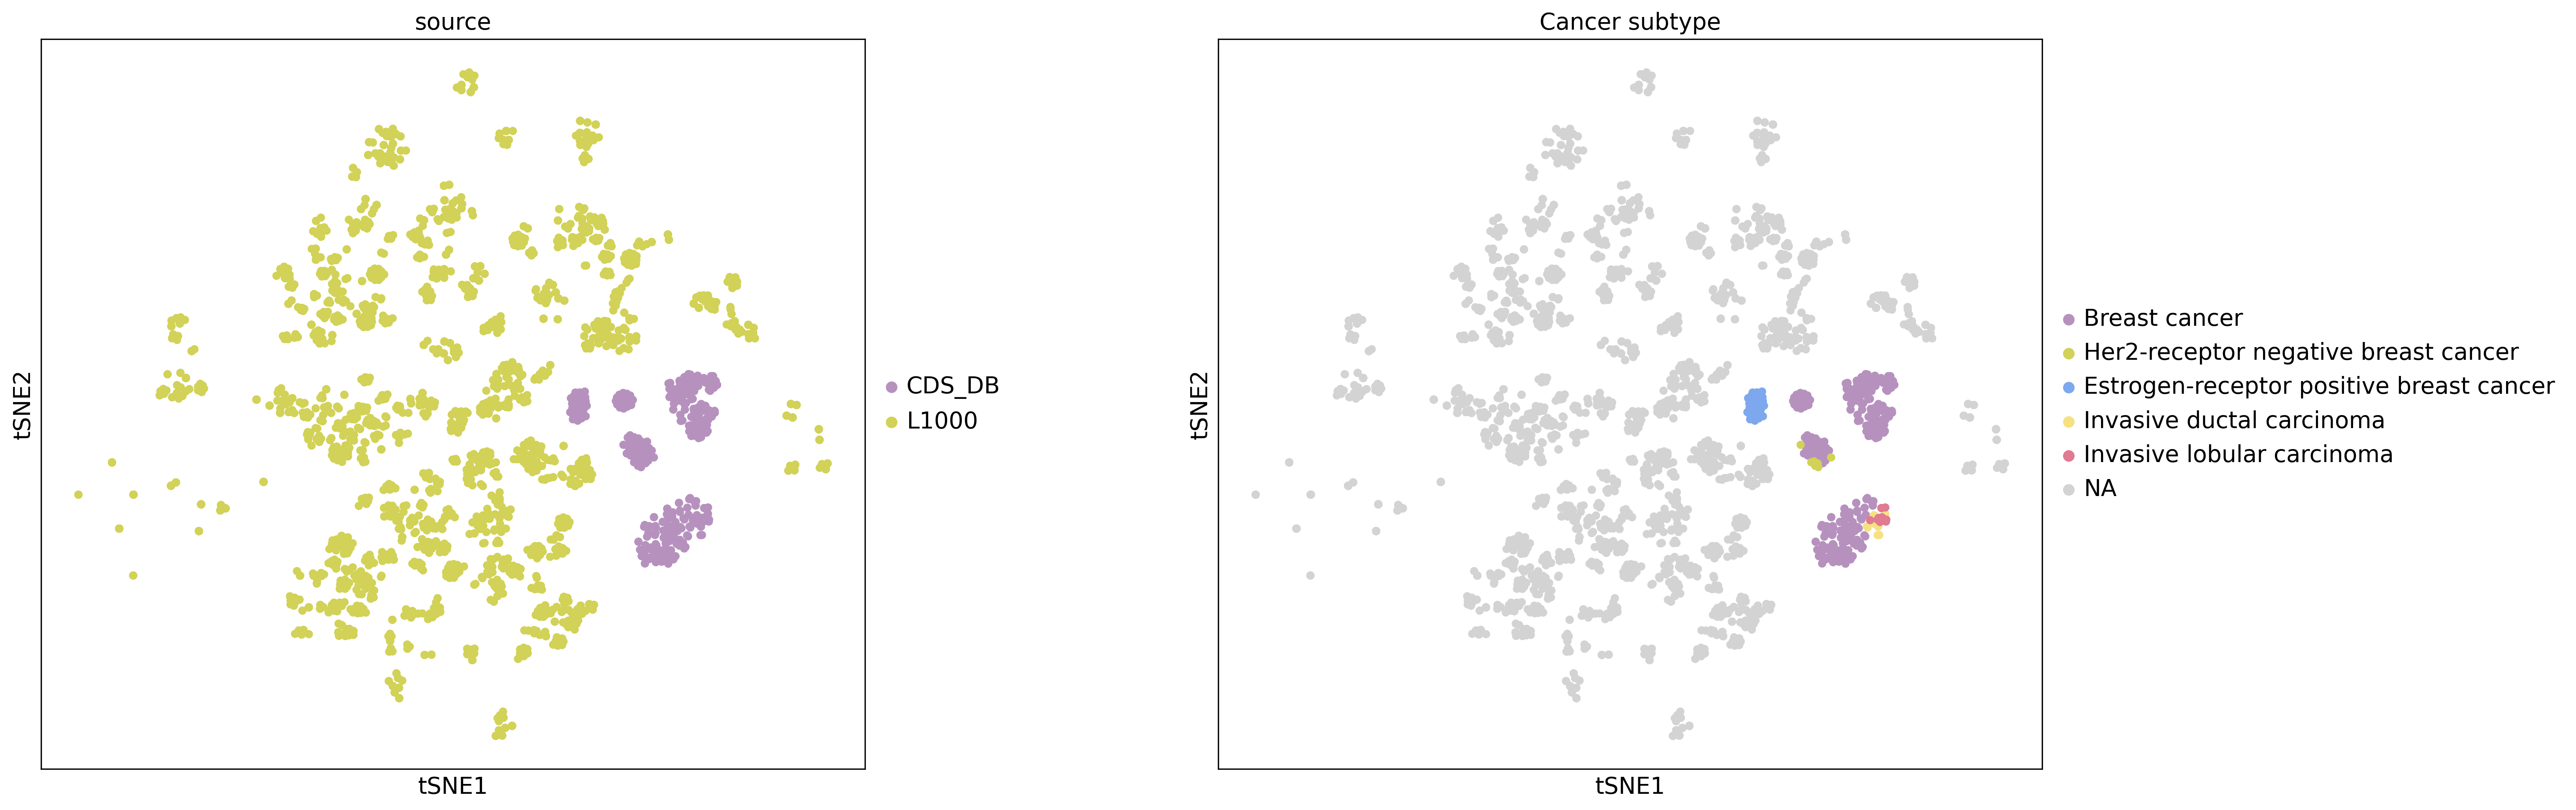

In [30]:
sc.pp.pca(plot_adata, n_comps=40)
sc.pp.neighbors(plot_adata, n_neighbors=15, use_rep='X_pca')
sc.tl.tsne(plot_adata)

sc.pl.tsne(plot_adata, color=["source", "Cancer subtype"], wspace=0.3, legend_fontsize=14, s=100, 
           palette=colors, alpha=1, show=False)

# plt.savefig("figs/tsne_l1000&cdsdb_breast_ctl.svg", format="svg", dpi=300, bbox_inches="tight")

In [142]:
a1 = adata1_breast_filter
a2 = adata2_breast

X_merge = np.concatenate((a1.obsm["ctl_cls_embed"], a2.obsm["ctl_cls_embed"]), axis=0)

info1 = a1.obs[['cell_iname', 'tissue']].copy()
info2 = a2.obs[['Cancer subtype', 'tissue']].copy()
info1.loc[:, 'source'] = 'L1000'
info2.loc[:, 'source'] = 'CDS_DB'
info_merge = pd.concat([info1, info2], axis=0)

plot_adata = sc.AnnData(X=X_merge)
plot_adata.obs = info_merge

plot_adata

AnnData object with n_obs × n_vars = 3357 × 256
    obs: 'cell_iname', 'tissue', 'source', 'Cancer subtype'

computing PCA
    with n_comps=40
    finished (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:05)


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.

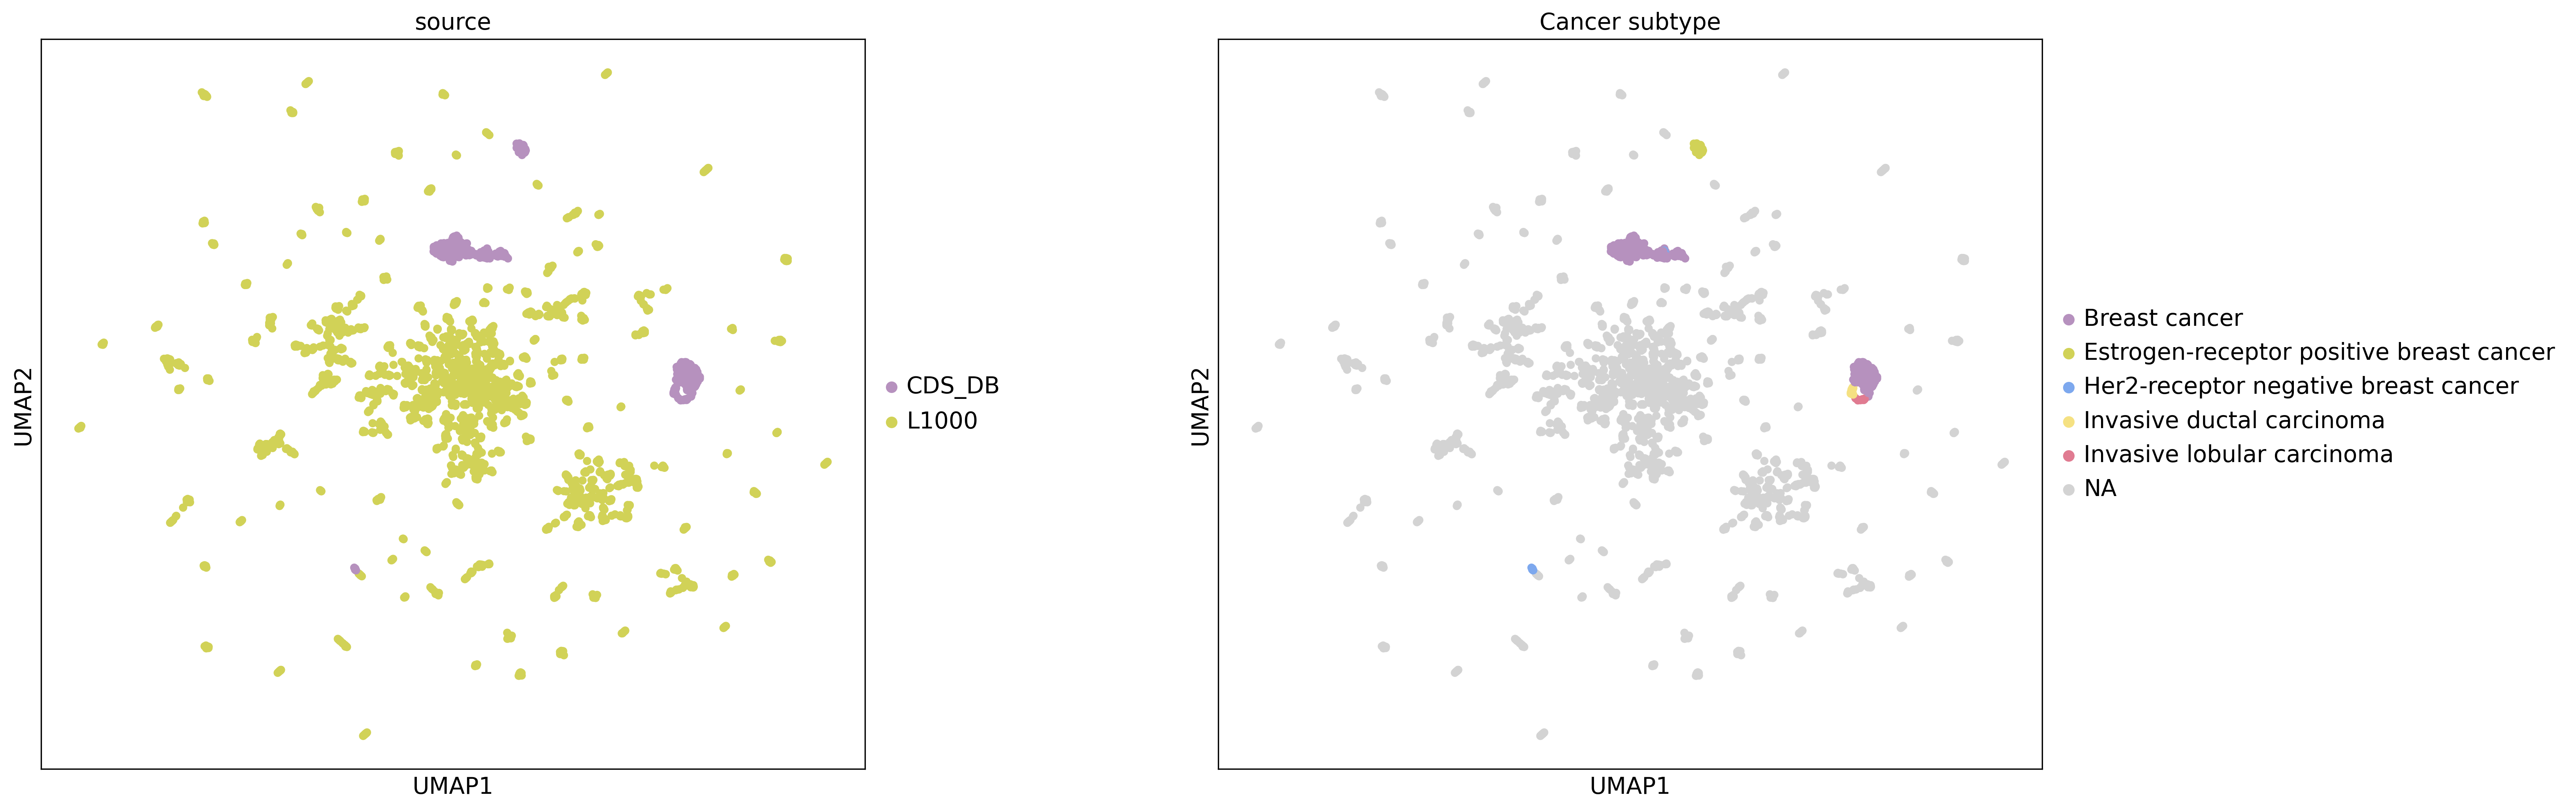

In [143]:
sc.pp.pca(plot_adata, n_comps=40)
sc.pp.neighbors(plot_adata, n_neighbors=15, use_rep='X_pca')
sc.tl.umap(plot_adata)

sc.pl.umap(plot_adata, color=["source", "Cancer subtype"], wspace=0.3, legend_fontsize=14, 
           size=100, palette=colors)

computing tSNE
    using 'X_pca' with n_pcs = 40
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:05)


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.

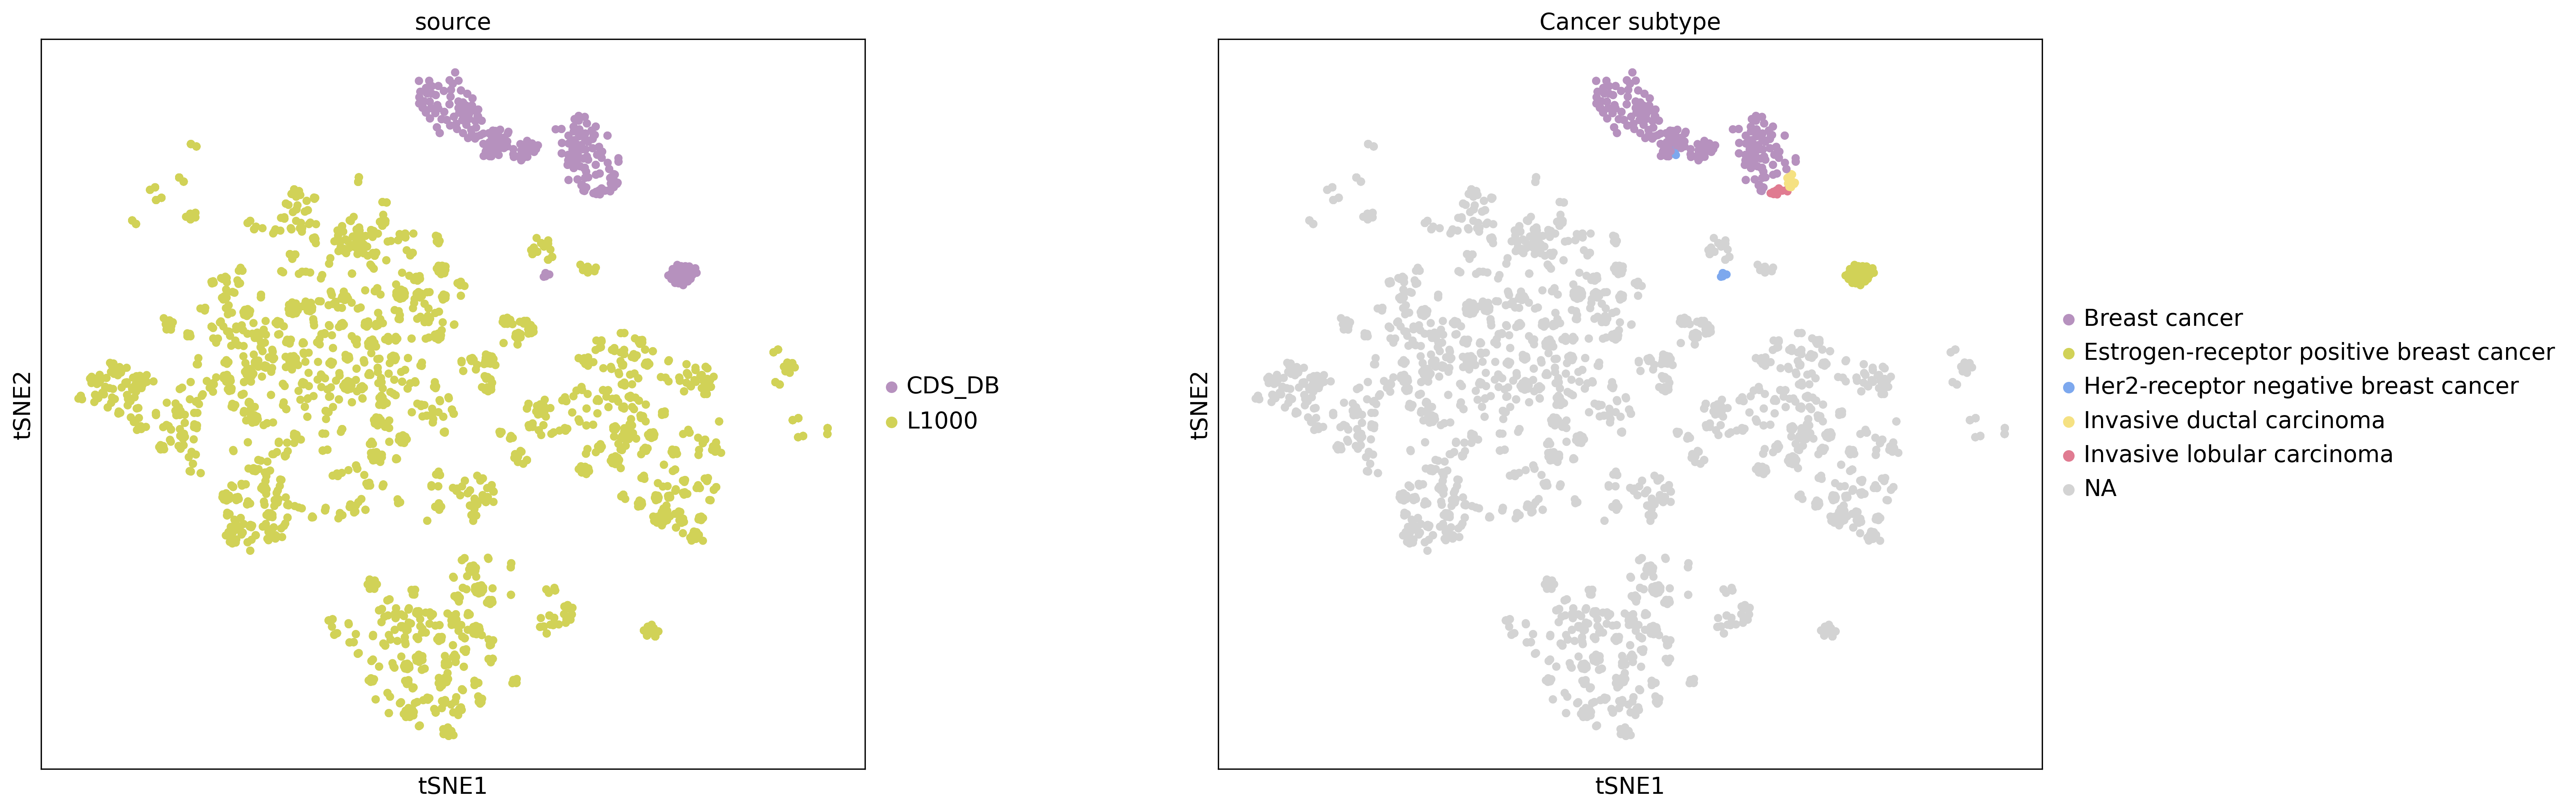

In [144]:
sc.tl.tsne(plot_adata)

sc.pl.tsne(plot_adata, color=["source", "Cancer subtype"], wspace=0.3, legend_fontsize=14, s=100, 
           palette=colors, alpha=1)

# Visualize post-treament space (L1000_breast & cdsdb_breast)

In [31]:
a1 = adata1_breast_filter
a2 = adata2_breast

X_merge = np.concatenate((a1.X, a2.X), axis=0)

info1 = a1.obs[['cell_iname', 'tissue']].copy()
info2 = a2.obs[['Cancer subtype', 'tissue']].copy()
info1.loc[:, 'source'] = 'L1000'
info2.loc[:, 'source'] = 'CDS_DB'
info_merge = pd.concat([info1, info2], axis=0)

plot_adata = sc.AnnData(X=X_merge)
plot_adata.obs = info_merge

plot_adata

AnnData object with n_obs × n_vars = 3357 × 978
    obs: 'cell_iname', 'tissue', 'source', 'Cancer subtype'

computing PCA
    with n_comps=40
    finished (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 40
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:05)


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.

[<Axes: title={'center': 'source'}, xlabel='tSNE1', ylabel='tSNE2'>,
 <Axes: title={'center': 'Cancer subtype'}, xlabel='tSNE1', ylabel='tSNE2'>]

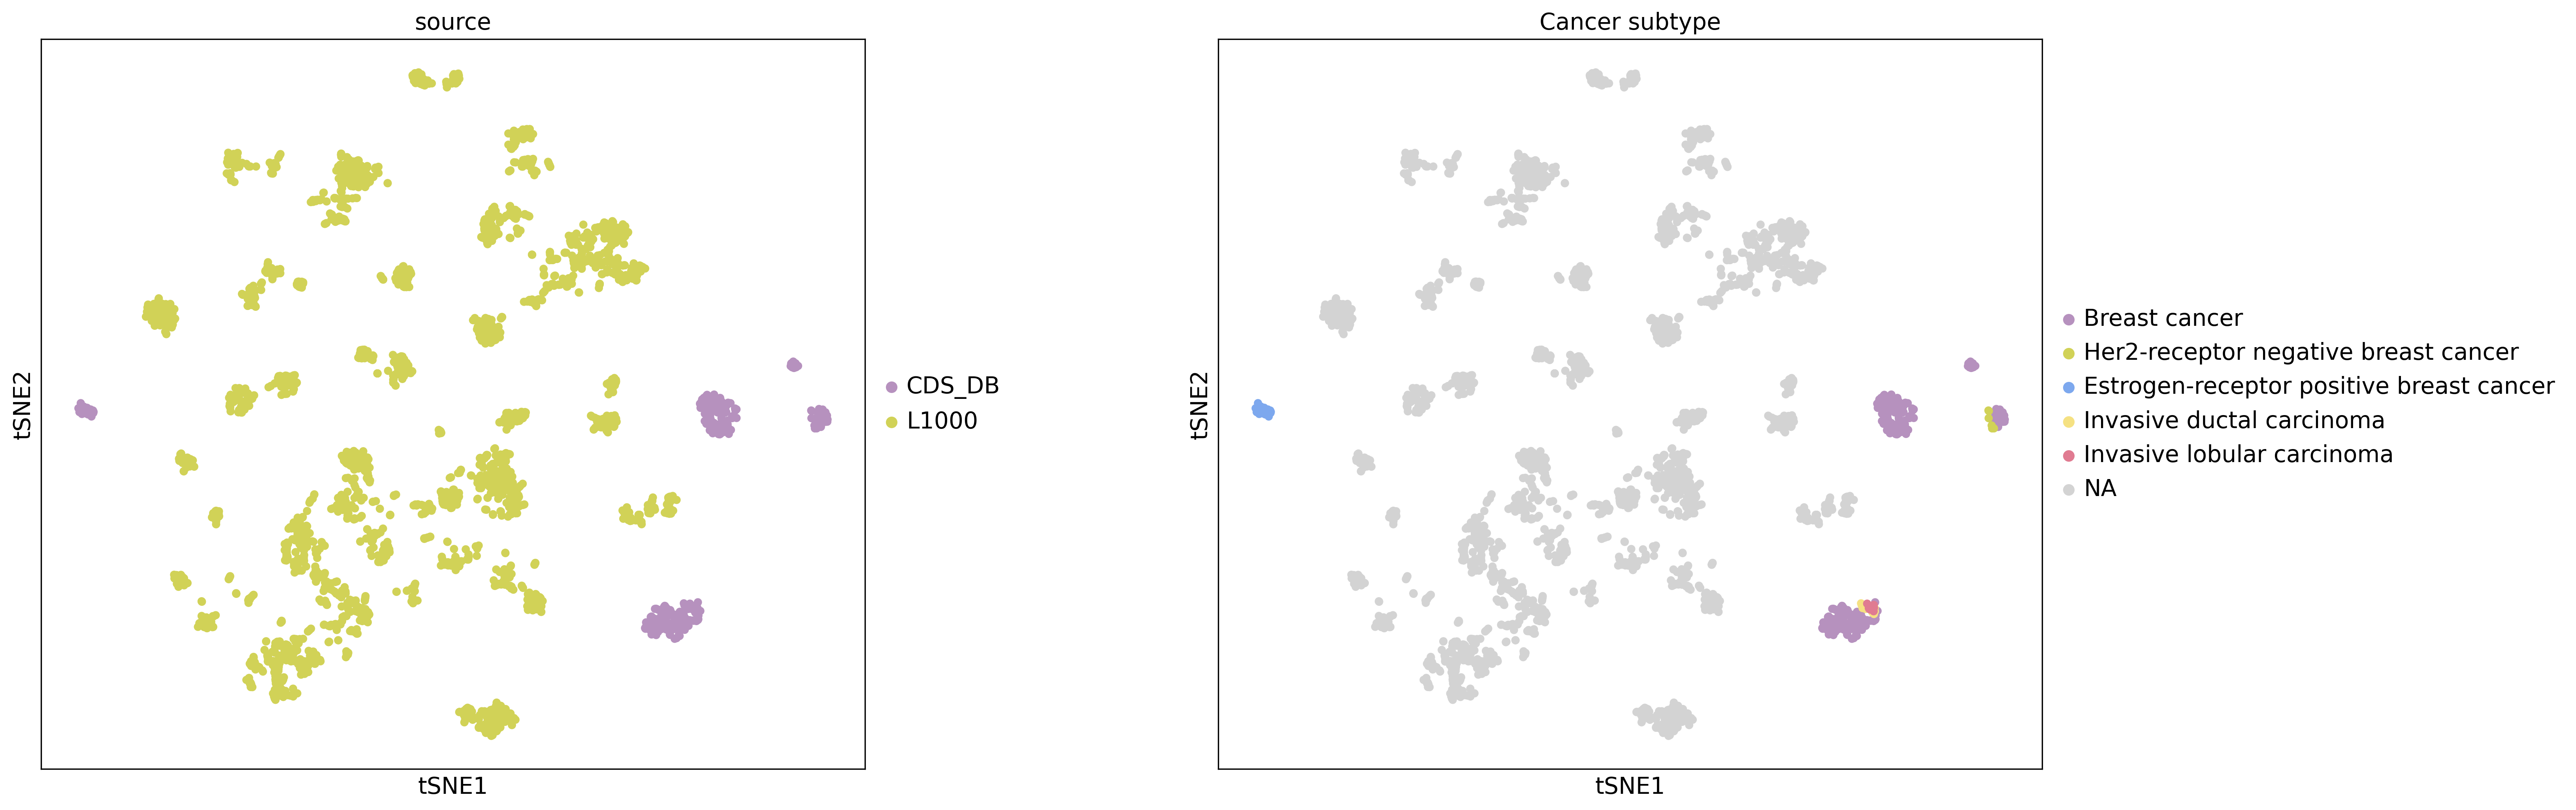

In [33]:
sc.pp.pca(plot_adata, n_comps=40)
sc.pp.neighbors(plot_adata, n_neighbors=15, use_rep='X_pca')

sc.tl.tsne(plot_adata)

sc.pl.tsne(plot_adata, color=["source", "Cancer subtype"], wspace=0.3, legend_fontsize=14, s=100, 
           palette=colors, alpha=1, show=False)

# plt.savefig("figs/tsne_l1000&cdsdb_breast_trt.svg", format="svg", dpi=300, bbox_inches="tight")

# Visualize pre-treament space (L1000_HL & cdsdb_leukemia)

In [34]:
n_samples = 5000
adata1_leukemia_filter_samples, _ = train_test_split(adata1_leukemia.obs, train_size=n_samples, random_state=42)
adata1_leukemia_filter = adata1_leukemia[adata1_leukemia.obs.index.isin(adata1_leukemia_filter_samples.index)]

In [35]:
a1 = adata1_leukemia_filter
a2 = adata2_leukemia

X_merge = np.concatenate((a1.obsm['X_ctl'], a2.obsm['X_ctl']), axis=0)

info1 = a1.obs[['cell_iname', 'tissue']].copy()
info2 = a2.obs[['Cancer subtype', 'tissue']].copy()
info1.loc[:, 'source'] = 'L1000'
info2.loc[:, 'source'] = 'CDS_DB'
info_merge = pd.concat([info1, info2], axis=0)

plot_adata = sc.AnnData(X=X_merge)
plot_adata.obs = info_merge

plot_adata

AnnData object with n_obs × n_vars = 5196 × 978
    obs: 'cell_iname', 'tissue', 'source', 'Cancer subtype'

computing PCA
    with n_comps=40
    finished (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 40
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:06)


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.

[<Axes: title={'center': 'source'}, xlabel='tSNE1', ylabel='tSNE2'>,
 <Axes: title={'center': 'Cancer subtype'}, xlabel='tSNE1', ylabel='tSNE2'>]

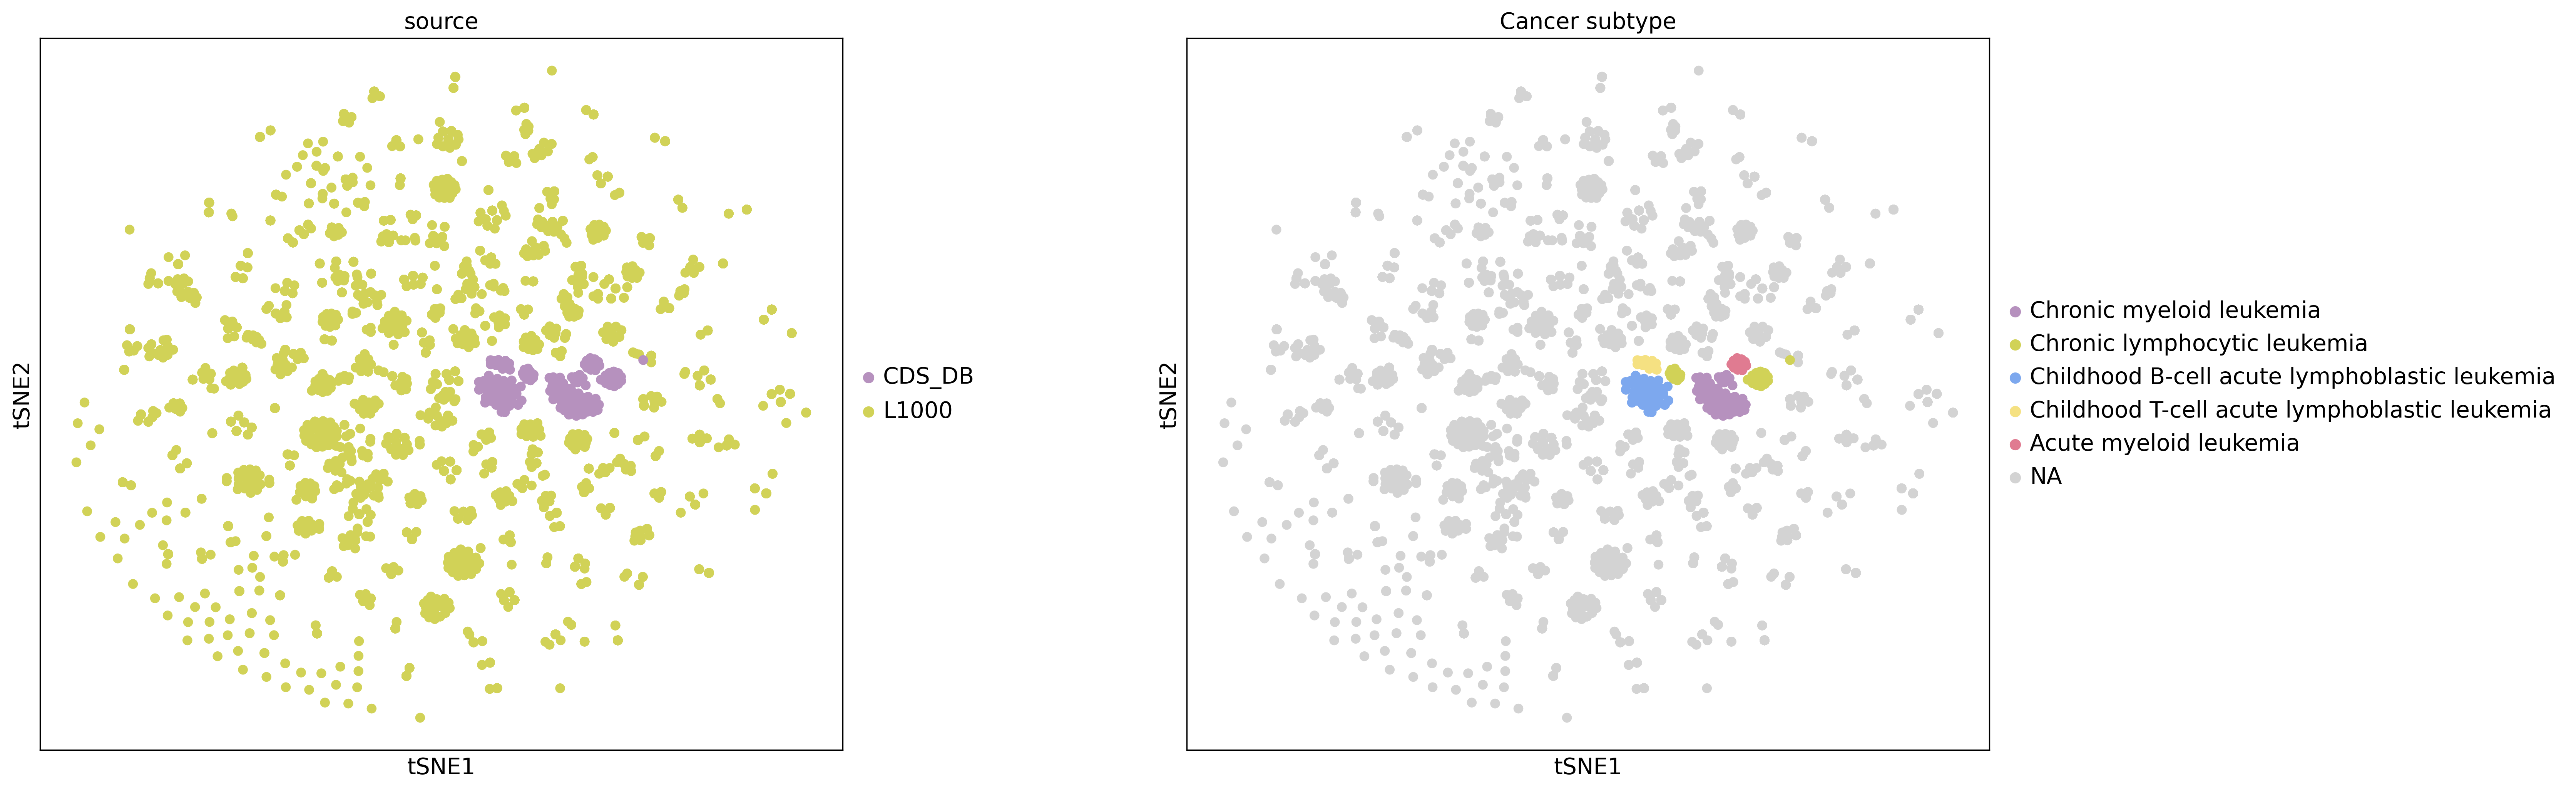

In [36]:
sc.pp.pca(plot_adata, n_comps=40)
sc.pp.neighbors(plot_adata, n_neighbors=15, use_rep='X_pca')
sc.tl.tsne(plot_adata)

sc.pl.tsne(plot_adata, color=["source", "Cancer subtype"], wspace=0.3, legend_fontsize=14, 
           size=150, palette=colors, show=False)

# plt.savefig("figs/tsne_l1000&cdsdb_leukemia_ctl.svg", format="svg", dpi=300, bbox_inches="tight")

# Visualize post-treament space (L1000_HL & cdsdb_leukemia)

In [37]:
a1 = adata1_leukemia_filter
a2 = adata2_leukemia

X_merge = np.concatenate((a1.X, a2.X), axis=0)

info1 = a1.obs[['cell_iname', 'tissue']].copy()
info2 = a2.obs[['Cancer subtype', 'tissue']].copy()
info1.loc[:, 'source'] = 'L1000'
info2.loc[:, 'source'] = 'CDS_DB'
info_merge = pd.concat([info1, info2], axis=0)

plot_adata = sc.AnnData(X=X_merge)
plot_adata.obs = info_merge

plot_adata

AnnData object with n_obs × n_vars = 5196 × 978
    obs: 'cell_iname', 'tissue', 'source', 'Cancer subtype'

computing PCA
    with n_comps=40
    finished (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 40
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:09)


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.

[<Axes: title={'center': 'source'}, xlabel='tSNE1', ylabel='tSNE2'>,
 <Axes: title={'center': 'Cancer subtype'}, xlabel='tSNE1', ylabel='tSNE2'>]

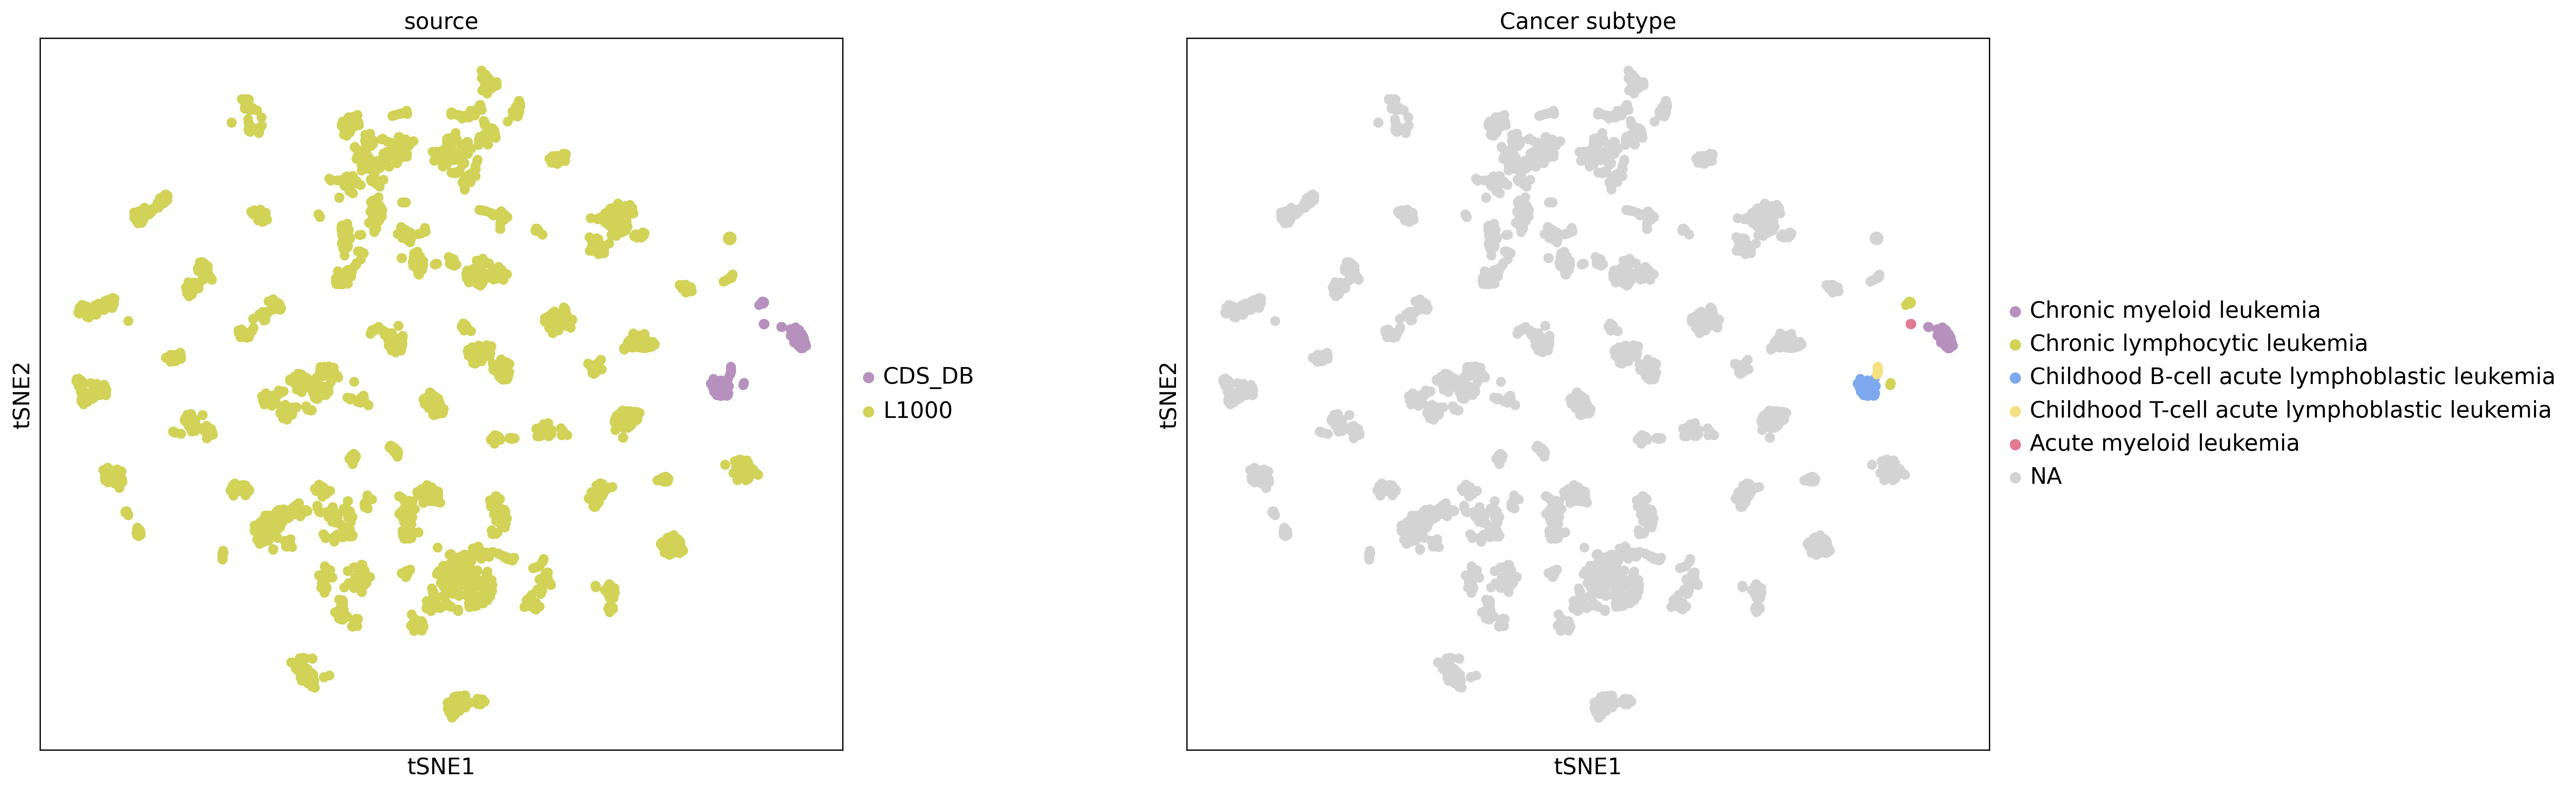

In [38]:
sc.pp.pca(plot_adata, n_comps=40)
sc.pp.neighbors(plot_adata, n_neighbors=15, use_rep='X_pca')
sc.tl.tsne(plot_adata)

sc.pl.tsne(plot_adata, color=["source", "Cancer subtype"], wspace=0.3, legend_fontsize=14, size=150, palette=colors,
          show=False)

# plt.savefig("figs/tsne_l1000&cdsdb_leukemia_trt.svg", format="svg", dpi=300, bbox_inches="tight")

In [135]:
a1 = adata1_breast_filter
a2 = adata2_breast

X_merge = np.concatenate((a1.obsm["trt_cls_embed"], a2.obsm["trt_cls_embed"]), axis=0)

info1 = a1.obs[['cell_iname', 'tissue']].copy()
info2 = a2.obs[['Cancer subtype', 'tissue']].copy()
info1.loc[:, 'source'] = 'L1000'
info2.loc[:, 'source'] = 'CDS_DB'
info_merge = pd.concat([info1, info2], axis=0)

plot_adata = sc.AnnData(X=X_merge)
plot_adata.obs = info_merge

plot_adata

AnnData object with n_obs × n_vars = 3357 × 256
    obs: 'cell_iname', 'tissue', 'source', 'Cancer subtype'

computing PCA
    with n_comps=40
    finished (0:00:00)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:04)


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.

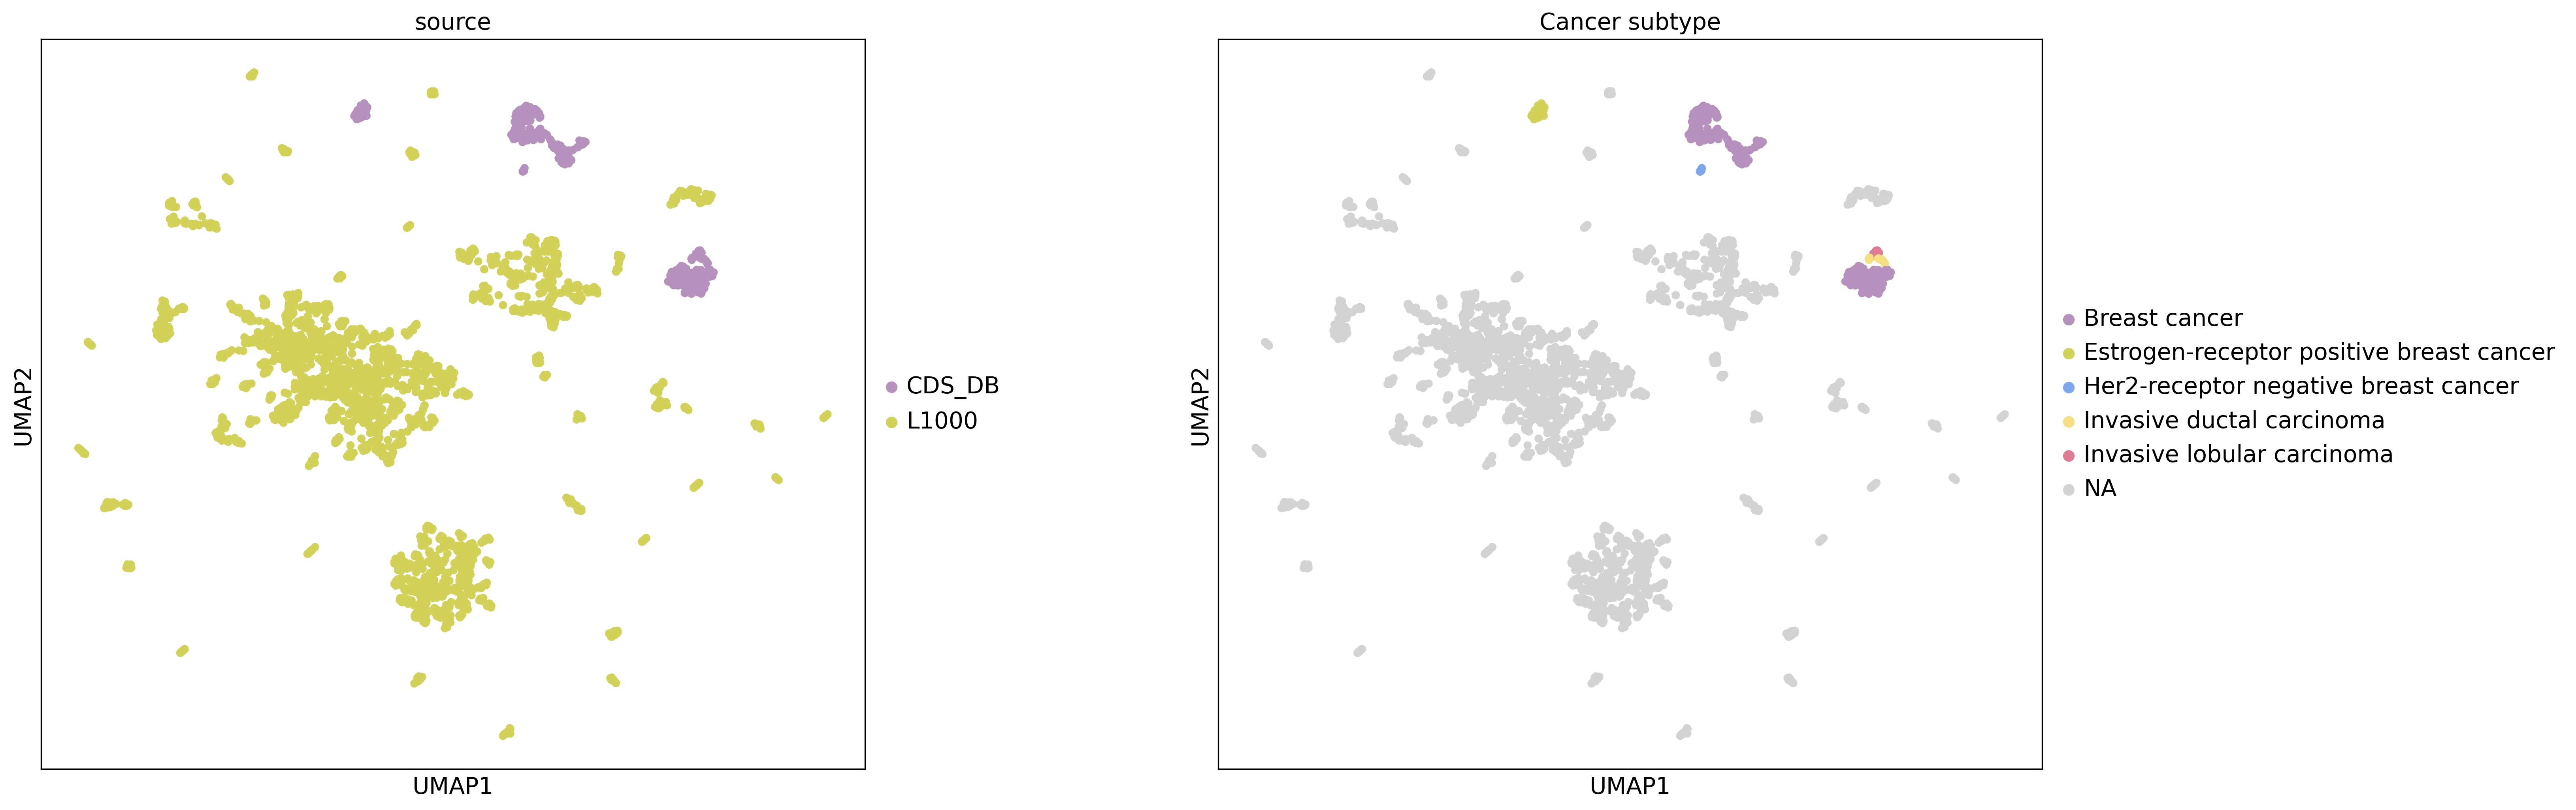

In [136]:
sc.pp.pca(plot_adata, n_comps=40)
sc.pp.neighbors(plot_adata, n_neighbors=15, use_rep='X_pca')
sc.tl.umap(plot_adata)

sc.pl.umap(plot_adata, color=["source", "Cancer subtype"], wspace=0.3, legend_fontsize=14, size=100, palette=colors)

computing tSNE
    using 'X_pca' with n_pcs = 40
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:05)


/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/root/data1/GY/Mambaforge/envs/openbiomed/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.

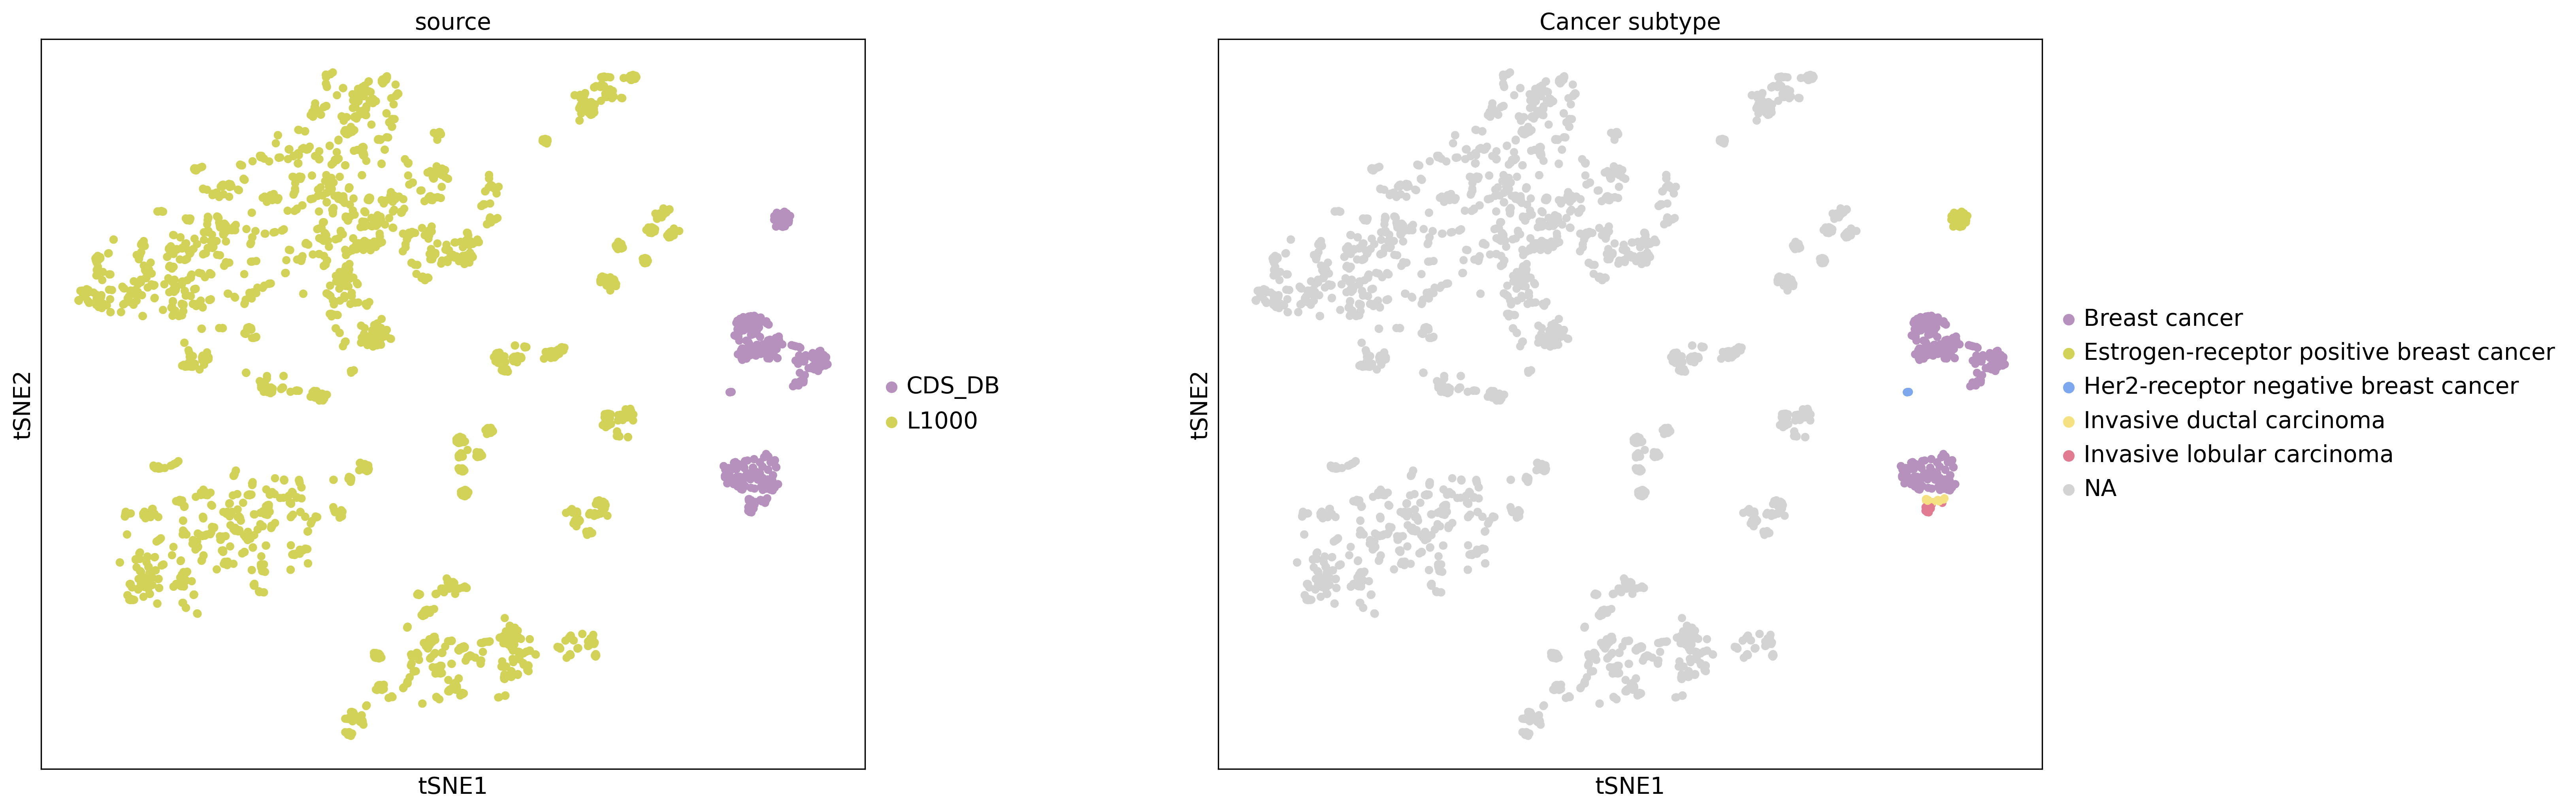

In [137]:
sc.tl.tsne(plot_adata)

sc.pl.tsne(plot_adata, color=["source", "Cancer subtype"], wspace=0.3, legend_fontsize=14, s=100, 
           palette=colors, alpha=1)